# ¿Qué factores operativos y comerciales están asociados con la cancelación de pedidos y con el valor del ticket en las ventas de Amazon India?

**Autora:** Sandy Alonso

Este proyecto analiza el reporte de ventas de Amazon India entre el 31 de marzo y el 29 de junio de 2022, a nivel de línea de pedido (SKU dentro de cada orden). El objetivo es identificar qué factores operativos (tipo de fulfilment, nivel de servicio de envío) y comerciales (promociones, categoría de producto, tipo de cliente B2B o B2C, estacionalidad) se asocian con la cancelación de pedidos y con el valor del ticket, para apoyar decisiones de operación y de estrategia comercial.

In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
df = pd.read_csv('../data/raw/Amazon Sale Report.csv', low_memory=False)

## Descripción de las columnas del dataset

El dataset original contiene 128,975 filas y 24 columnas, donde cada fila representa una línea de pedido (un SKU dentro de una orden de Amazon India):

- `index`: índice numérico del archivo original, no aporta información (se elimina en el Paso 3).
- `Order ID`: identificador del pedido, se puede repetir cuando el pedido tiene varias líneas (SKU).
- `Date`: fecha del pedido.
- `Status`: estatus del pedido (Shipped, Cancelled, Pending, entre otros).
- `Fulfilment`: quién despacha el pedido, Amazon o Merchant (vendedor).
- `Sales Channel `: canal de venta (Amazon.in o Non-Amazon). Trae un espacio al final en el nombre original.
- `ship-service-level`: nivel de servicio de envío (Standard o Expedited).
- `Style`: clave de estilo del producto.
- `SKU`: clave de inventario del producto.
- `Category`: categoría del producto (Set, kurta, Western Dress, entre otras).
- `Size`: talla del producto.
- `ASIN`: identificador único de producto en Amazon.
- `Courier Status`: estatus de la paquetería (Shipped, Cancelled, Unshipped).
- `Qty`: cantidad de unidades vendidas en la línea de pedido.
- `currency`: moneda de la transacción, en la práctica solo toma el valor INR o nulo.
- `Amount`: monto de la venta en la línea de pedido.
- `ship-city`: ciudad de envío.
- `ship-state`: estado de envío.
- `ship-postal-code`: código postal de envío.
- `ship-country`: país de envío, en la práctica solo toma el valor IN o nulo.
- `promotion-ids`: identificadores de promociones aplicadas al pedido (puede haber varias, separadas por coma).
- `B2B`: si el pedido es de negocio a negocio (True) o de negocio a consumidor (False).
- `fulfilled-by`: quién ejecuta físicamente el envío cuando el fulfilment es Merchant (Easy Ship). Es redundante con `Fulfilment`.
- `Unnamed: 22`: columna sin nombre ni contenido útil, artefacto de la exportación del archivo original.

Nota sobre los demás archivos de `data/raw/`: `Cloud Warehouse Compersion Chart.csv`, `Expense IIGF.csv`, `International sale Report.csv`, `May-2022.csv`, `P  L March 2021.csv` y `Sale Report.csv` quedan fuera de alcance de este análisis. No se relacionan de forma limpia con el reporte de Amazon (son reportes de inventario, gastos, ventas internacionales o estados de resultados con estructura y periodos distintos), así que este proyecto se enfoca únicamente en `Amazon Sale Report.csv`.

## Preguntas que guían el análisis

1. ¿El tipo de fulfilment (Amazon o Merchant) está asociado con la cancelación de pedidos?
2. ¿Las promociones se asocian con un ticket distinto y con una tasa de cancelación distinta?
3. ¿El ticket promedio difiere entre categorías de producto?
4. ¿El nivel de servicio de envío (Expedited o Standard) está asociado con la cancelación, y esa relación se mantiene dentro de cada tipo de fulfilment?
5. ¿El ticket cambia entre meses y entre fin de semana y días hábiles?
6. ¿Los pedidos B2B tienen un ticket distinto a los B2C?

## Paso 1: Carga de datos y vista rápida

### 1.1 Head y Tail del dataset

In [3]:
print("Head of DataFrame:")
print(df.head())

Head of DataFrame:
   index             Order ID      Date                        Status  \
0      0  405-8078784-5731545  04-30-22                     Cancelled   
1      1  171-9198151-1101146  04-30-22  Shipped - Delivered to Buyer   
2      2  404-0687676-7273146  04-30-22                       Shipped   
3      3  403-9615377-8133951  04-30-22                     Cancelled   
4      4  407-1069790-7240320  04-30-22                       Shipped   

  Fulfilment Sales Channel  ship-service-level    Style              SKU  \
0   Merchant      Amazon.in           Standard   SET389   SET389-KR-NP-S   
1   Merchant      Amazon.in           Standard  JNE3781  JNE3781-KR-XXXL   
2     Amazon      Amazon.in          Expedited  JNE3371    JNE3371-KR-XL   
3   Merchant      Amazon.in           Standard    J0341       J0341-DR-L   
4     Amazon      Amazon.in          Expedited  JNE3671  JNE3671-TU-XXXL   

        Category  ... currency  Amount    ship-city   ship-state  \
0            Set 

In [4]:
print("Tail of DataFrame:")
print(df.tail())

Tail of DataFrame:
         index             Order ID      Date   Status Fulfilment  \
128970  128970  406-6001380-7673107  05-31-22  Shipped     Amazon   
128971  128971  402-9551604-7544318  05-31-22  Shipped     Amazon   
128972  128972  407-9547469-3152358  05-31-22  Shipped     Amazon   
128973  128973  402-6184140-0545956  05-31-22  Shipped     Amazon   
128974  128974  408-7436540-8728312  05-31-22  Shipped     Amazon   

       Sales Channel  ship-service-level    Style             SKU  \
128970      Amazon.in          Expedited  JNE3697   JNE3697-KR-XL   
128971      Amazon.in          Expedited   SET401  SET401-KR-NP-M   
128972      Amazon.in          Expedited    J0157    J0157-DR-XXL   
128973      Amazon.in          Expedited    J0012    J0012-SKD-XS   
128974      Amazon.in          Expedited    J0003     J0003-SET-S   

             Category  ... currency  Amount  ship-city    ship-state  \
128970          kurta  ...      INR   517.0  HYDERABAD     TELANGANA   
128971 

**Objetivo:**
Confirmar el tamaño del dataset y revisar la estructura general antes de avanzar al análisis de calidad de datos.

In [5]:
# forma del dataset
print(df.shape)

(128975, 24)


In [6]:
# información general: tipos de datos y nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 24 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   index               128975 non-null  int64  
 1   Order ID            128975 non-null  str    
 2   Date                128975 non-null  str    
 3   Status              128975 non-null  str    
 4   Fulfilment          128975 non-null  str    
 5   Sales Channel       128975 non-null  str    
 6   ship-service-level  128975 non-null  str    
 7   Style               128975 non-null  str    
 8   SKU                 128975 non-null  str    
 9   Category            128975 non-null  str    
 10  Size                128975 non-null  str    
 11  ASIN                128975 non-null  str    
 12  Courier Status      122103 non-null  str    
 13  Qty                 128975 non-null  int64  
 14  currency            121180 non-null  str    
 15  Amount              121180 non-null  float64


In [7]:
# tipos de datos por columna
print(df.dtypes)

index                   int64
Order ID                  str
Date                      str
Status                    str
Fulfilment                str
Sales Channel             str
ship-service-level        str
Style                     str
SKU                       str
Category                  str
Size                      str
ASIN                      str
Courier Status            str
Qty                     int64
currency                  str
Amount                float64
ship-city                 str
ship-state                str
ship-postal-code      float64
ship-country              str
promotion-ids             str
B2B                      bool
fulfilled-by              str
Unnamed: 22            object
dtype: object


**Comentario:**
El dataset tiene 128,975 filas y 24 columnas. La columna `index` y `Unnamed: 22` son artefactos del archivo original. Hay columnas numéricas (`Qty`, `Amount`, `ship-postal-code`), una columna booleana (`B2B`) y el resto son columnas de texto (identificadores, fechas como texto, estatus, categorías de producto y ubicación de envío). En la siguiente sección revisamos nulos, duplicados y valores sospechosos.

## Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**Objetivo:**
Cuantificar los valores nulos por columna, en conteo y en porcentaje.

In [8]:
# cantidad y porcentaje de nulos por columna
tabla_nulos = pd.DataFrame({
    'nulos': df.isna().sum(),
    'porcentaje': (df.isna().mean() * 100).round(2)
})
print(tabla_nulos)

                    nulos  porcentaje
index                   0        0.00
Order ID                0        0.00
Date                    0        0.00
Status                  0        0.00
Fulfilment              0        0.00
Sales Channel           0        0.00
ship-service-level      0        0.00
Style                   0        0.00
SKU                     0        0.00
Category                0        0.00
Size                    0        0.00
ASIN                    0        0.00
Courier Status       6872        5.33
Qty                     0        0.00
currency             7795        6.04
Amount               7795        6.04
ship-city              33        0.03
ship-state             33        0.03
ship-postal-code       33        0.03
ship-country           33        0.03
promotion-ids       49153       38.11
B2B                     0        0.00
fulfilled-by        89698       69.55
Unnamed: 22         49050       38.03


**Comentario:**
Las columnas con nulos relevantes son `fulfilled-by` (89,698 filas, 69.55%), `promotion-ids` (49,153 filas, 38.11%), `Unnamed: 22` (49,050 filas, 38.03%), `Courier Status` (6,872 filas, 5.33%), `currency` y `Amount` (7,795 filas cada una, 6.04%). `ship-city`, `ship-state`, `ship-postal-code` y `ship-country` tienen 33 nulos cada una (0.03%). El resto de columnas está completo. En la sección 2.4 investigamos el mecanismo de los nulos de `Amount` y `Courier Status`, que son los más relevantes para las preguntas de negocio.

### 2.2 Revisión de duplicados

**Objetivo:**
Verificar si existen filas completas duplicadas (excluyendo `index`, que es solo un contador) y si `Order ID` se repite, para definir la unidad de análisis.

In [9]:
# duplicados: filas completas (sin contar index) y Order ID repetido
print('Filas duplicadas (excluyendo index):', df.drop(columns=['index']).duplicated().sum())
print('Filas con Order ID duplicado:', df['Order ID'].duplicated().sum())
print('Order ID únicos:', df['Order ID'].nunique())

Filas duplicadas (excluyendo index): 6
Filas con Order ID duplicado: 8597
Order ID únicos: 120378


**Comentario:**
Hay 6 filas completamente duplicadas (excluyendo `index`), que eliminamos en el Paso 3. Por otro lado, `Order ID` se repite en 8,597 filas: esto no es un error, un mismo pedido puede incluir varios productos (SKU) y cada uno genera una línea propia en el reporte. Del total de 128,975 filas, solo hay 120,378 valores únicos de `Order ID`. Por esto definimos la unidad de análisis como la línea de pedido (una fila = un SKU dentro de una orden), no el pedido completo.

### 2.3 Detección de valores inválidos y sentinels

**Objetivo:**
Revisar los rangos de las columnas numéricas, los valores únicos de columnas clave y detectar columnas basura, espacios sobrantes, columnas constantes y otras inconsistencias.

In [10]:
# columnas numéricas
print(df[['Qty', 'Amount', 'ship-postal-code']].describe())

                 Qty         Amount  ship-postal-code
count  128975.000000  121180.000000     128942.000000
mean        0.904431     648.561465     463966.236509
std         0.313354     281.211687     191476.764941
min         0.000000       0.000000     110001.000000
25%         1.000000     449.000000     382421.000000
50%         1.000000     605.000000     500033.000000
75%         1.000000     788.000000     600024.000000
max        15.000000    5584.000000     989898.000000


In [11]:
# ceros en Qty y Amount
print('Qty == 0:', (df['Qty'] == 0).sum())
print('Amount == 0:', (df['Amount'] == 0).sum())

Qty == 0: 12807
Amount == 0: 2343


In [12]:
# cruce de Qty == 0 y Amount == 0 contra Status
print(df.loc[df['Qty'] == 0, 'Status'].value_counts())
print()
print(df.loc[df['Amount'] == 0, 'Status'].value_counts())

Status
Cancelled                       12701
Shipped                            93
Shipped - Delivered to Buyer        8
Shipped - Returned to Seller        3
Pending                             2
Name: count, dtype: int64

Status
Shipped                          1518
Shipped - Delivered to Buyer      716
Shipped - Returned to Seller       51
Shipped - Picked Up                28
Pending                            17
Pending - Waiting for Pick Up       9
Shipped - Lost in Transit           2
Shipped - Returning to Seller       2
Name: count, dtype: int64


**Insights:**
`Qty` va de 0 a 15 unidades, con 12,807 filas en 0. De esas, 12,701 corresponden a pedidos con `Status` Cancelled, así que un `Qty` de 0 no es un error de captura sino el reflejo natural de una cancelación (no se despachó ninguna unidad).

`Amount` va de 0 a 5,584, con 2,343 filas en 0. A diferencia de `Qty`, estos ceros están mayormente en pedidos con `Status` Shipped (1,518) o Shipped - Delivered to Buyer (716), no en cancelados. Esto sí es más raro (un envío exitoso con monto 0), pero lo dejamos como está: podría corresponder a artículos de regalo, canje de puntos o algún ajuste comercial. No lo tratamos como error de captura, pero lo documentamos como un valor atípico a considerar en el análisis del ticket.

`ship-postal-code` tiene un rango consistente con códigos postales de India (5 dígitos), sin valores negativos ni fuera de escala.

In [13]:
# columna basura y espacio en el nombre de Sales Channel
print(df['Unnamed: 22'].unique())
print(repr(df.columns[5]))

[nan False]
'Sales Channel '


In [14]:
# columnas constantes: currency y ship-country
print(df['currency'].unique())
print(df['ship-country'].unique())

<StringArray>
['INR', nan]
Length: 2, dtype: str
<StringArray>
['IN', nan]
Length: 2, dtype: str


In [15]:
# fulfilled-by vs Fulfilment
print(pd.crosstab(df['Fulfilment'], df['fulfilled-by'], dropna=False))

fulfilled-by  Easy Ship    NaN
Fulfilment                    
Amazon                0  89698
Merchant          39277      0


In [16]:
# Category: revisar consistencia de mayúsculas
print(df['Category'].unique())

<StringArray>
[          'Set',         'kurta', 'Western Dress',           'Top',
  'Ethnic Dress',        'Bottom',         'Saree',        'Blouse',
       'Dupatta']
Length: 9, dtype: str


In [17]:
# ship-state: inconsistencias de mayúsculas y variantes
print('valores únicos crudos:', df['ship-state'].nunique())
estado_normalizado = df['ship-state'].dropna().str.strip().str.upper()
print('valores únicos tras strip/upper:', estado_normalizado.nunique())
print(estado_normalizado.value_counts().tail(15))

valores únicos crudos: 69


valores únicos tras strip/upper: 47


ship-state
NEW DELHI                 81
MIZORAM                   76
DADRA AND NAGAR           70
LADAKH                    43
LAKSHADWEEP                4
RAJSHTHAN                  3
ORISSA                     3
NL                         2
RJ                         2
RAJSTHAN                   2
PUNJAB/MOHALI/ZIRAKPUR     1
PB                         1
APO                        1
AR                         1
PONDICHERRY                1
Name: count, dtype: int64


**Insights:**
- `Unnamed: 22` es una columna basura: solo toma los valores nulo (49,050 filas) o `False` (79,925 filas), no aporta información y se elimina en el Paso 3.
- La columna de canal de venta se llama literalmente `'Sales Channel '`, con un espacio al final, un detalle de captura que corregimos al renombrar columnas.
- `currency` solo toma el valor INR (o nulo) y `ship-country` solo toma el valor IN (o nulo): son columnas constantes que no aportan variabilidad y se eliminan.
- `fulfilled-by` es redundante con `Fulfilment`: el crosstab muestra que cuando `Fulfilment` es Merchant, `fulfilled-by` siempre es Easy Ship (39,277 filas), y cuando `Fulfilment` es Amazon, `fulfilled-by` siempre es nulo (89,698 filas). No agrega información nueva, así que se elimina.
- `Category` tiene la categoría 'kurta' en minúscula (49,877 filas) mientras el resto de categorías empiezan con mayúscula (Set, Western Dress, Top, entre otras). Se corrige a formato título en el Paso 3.
- `ship-state` tiene 69 valores únicos crudos, pero solo 47 después de normalizar mayúsculas y espacios. Quedan variantes de escritura (abreviaturas como RJ, PB, AR, NL; nombres antiguos como Orissa en vez de Odisha, o Pondicherry en vez de Puducherry; y errores ortográficos como Rajshthan o Rajsthan) que unificamos en el Paso 3.

In [18]:
# cobertura de fechas
fechas = pd.to_datetime(df['Date'], format='%m-%d-%y')
print(fechas.min(), 'a', fechas.max())
print(fechas.dt.to_period('M').value_counts().sort_index())

2022-03-31 00:00:00 a 2022-06-29 00:00:00
Date
2022-03      171
2022-04    49067
2022-05    42040
2022-06    37697
Freq: M, Name: count, dtype: int64


**Insights:**
El dataset cubre del 31 de marzo al 29 de junio de 2022. Marzo solo tiene 171 filas, todas del día 31 de marzo, es decir, un mes incompleto (un solo día en vez de un mes completo), mientras que abril, mayo y junio sí están completos (49,067, 42,040 y 37,697 filas respectivamente). Para no distorsionar las comparaciones mensuales del Paso 4, excluimos las filas del 31 de marzo en el Paso 3 y trabajamos solo con abril, mayo y junio.

### 2.4 Mecanismo de los valores nulos

**Objetivo:**
Investigar si los nulos de `Amount` dependen de `Status` (si el pedido fue cancelado o no) y de `Fulfilment`, y si los nulos de `Courier Status` dependen de `Status`, para decidir si el mecanismo es MAR o MCAR y así definir el tratamiento en el Paso 3.

In [19]:
# indicador de nulo en Amount y cruce con Status y Fulfilment
df['amount_nulo'] = df['Amount'].isna()

tabla_status = pd.crosstab(df['amount_nulo'], df['Status'])
chi2_status, p_status, dof_status, exp_status = stats.chi2_contingency(tabla_status)
print(f'amount_nulo vs Status: chi2 = {chi2_status:.2f}, p = {p_status:.4g}')

tabla_fulfilment = pd.crosstab(df['amount_nulo'], df['Fulfilment'])
chi2_fulf, p_fulf, dof_fulf, exp_fulf = stats.chi2_contingency(tabla_fulfilment)
print(f'amount_nulo vs Fulfilment: chi2 = {chi2_fulf:.2f}, p = {p_fulf:.4g}')

print()
print('porcentaje de amount nulo por Status:')
print((df.groupby('Status')['amount_nulo'].mean() * 100).round(2))

amount_nulo vs Status: chi2 = 46844.88, p = 0
amount_nulo vs Fulfilment: chi2 = 261.86, p = 6.741e-59

porcentaje de amount nulo por Status:


Status
Cancelled                         41.27
Pending                            0.30
Pending - Waiting for Pick Up      0.00
Shipped                            0.27
Shipped - Damaged                  0.00
Shipped - Delivered to Buyer       0.03
Shipped - Lost in Transit          0.00
Shipped - Out for Delivery         0.00
Shipped - Picked Up                0.00
Shipped - Rejected by Buyer        0.00
Shipped - Returned to Seller       0.15
Shipped - Returning to Seller      0.00
Shipping                         100.00
Name: amount_nulo, dtype: float64


In [20]:
# indicador de nulo en Courier Status y cruce con Status
df['courier_nulo'] = df['Courier Status'].isna()

tabla_courier = pd.crosstab(df['courier_nulo'], df['Status'])
chi2_cour, p_cour, dof_cour, exp_cour = stats.chi2_contingency(tabla_courier)
print(f'courier_nulo vs Status: chi2 = {chi2_cour:.2f}, p = {p_cour:.4g}')

courier_nulo vs Status: chi2 = 43647.10, p = 0


**Insights:**
Los resultados de las pruebas de chi cuadrado son:

- `amount_nulo` vs `Status`: chi2 = 46,844.88, p menor a 0.0001 (altamente significativo).
- `amount_nulo` vs `Fulfilment`: chi2 = 261.86, p menor a 0.0001 (altamente significativo).
- `courier_nulo` vs `Status`: chi2 = 43,647.10, p menor a 0.0001 (altamente significativo).

El desglose por `Status` confirma el patrón: el 41.27% de los pedidos Cancelled tienen `Amount` nulo, contra menos del 0.3% en el resto de los estatus (Shipped 0.27%, Shipped - Delivered to Buyer 0.03%), con la excepción del estatus Shipping, que solo tiene 8 filas y las 8 tienen `Amount` nulo. Esto es un mecanismo MAR (Missing At Random): el nulo de `Amount` depende directamente de si el pedido fue cancelado, no ocurre al azar. Por eso decidimos no imputar `Amount`: un monto nulo en un pedido cancelado no es un dato faltante que debamos rellenar, es la ausencia natural de una venta que no se concretó. Lo mismo aplica para `courier_nulo`, que también depende fuertemente de `Status` (los pedidos cancelados casi nunca llegan a tener un estatus de paquetería).

### Observaciones del Paso 2

En resumen, el dataset tiene un problema de calidad menor en términos de duplicados (6 filas completas y `Order ID` repetido por diseño, ya que un pedido puede tener varias líneas) y varios problemas de formato y consistencia (columna basura `Unnamed: 22`, espacio en el nombre de `Sales Channel `, columnas constantes `currency` y `ship-country`, columna redundante `fulfilled-by`, inconsistencia de mayúsculas en `Category` y en `ship-state`, y un mes de marzo incompleto). Los nulos más relevantes, los de `Amount` y `Courier Status`, siguen un mecanismo MAR: dependen de si el pedido fue cancelado, por lo que no se imputan. Con este diagnóstico avanzamos a la limpieza básica en el Paso 3.

## Paso 3: Limpieza básica de datos

### 3.1 Eliminar columnas sin valor analítico

**Objetivo:**
Eliminar `index` (solo un contador sin información), `Unnamed: 22` (columna basura), `currency` y `ship-country` (columnas constantes, sin variabilidad) y `fulfilled-by` (redundante con `Fulfilment`, según confirmamos en 2.3).

In [21]:
# eliminar columnas sin valor analítico
df = df.drop(columns=['index', 'Unnamed: 22', 'currency', 'ship-country', 'fulfilled-by'])

# quitar columnas auxiliares de indicadores de nulo usadas en 2.4
df = df.drop(columns=['amount_nulo', 'courier_nulo'])

print(df.columns.tolist())

['Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ', 'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN', 'Courier Status', 'Qty', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'promotion-ids', 'B2B']


### 3.2 Renombrar columnas a snake_case

**Objetivo:**
Renombrar las columnas a snake_case en inglés, conservando los nombres originales (sin traducir), para tener nombres consistentes y fáciles de usar en el código.

In [22]:
# renombrar columnas a snake_case
df = df.rename(columns={
    'Order ID': 'order_id',
    'Date': 'date',
    'Status': 'status',
    'Fulfilment': 'fulfilment',
    'Sales Channel ': 'sales_channel',
    'ship-service-level': 'ship_service_level',
    'Style': 'style',
    'SKU': 'sku',
    'Category': 'category',
    'Size': 'size',
    'ASIN': 'asin',
    'Courier Status': 'courier_status',
    'Qty': 'qty',
    'Amount': 'amount',
    'ship-city': 'ship_city',
    'ship-state': 'ship_state',
    'ship-postal-code': 'ship_postal_code',
    'promotion-ids': 'promotion_ids',
    'B2B': 'b2b',
})

print(df.columns.tolist())

['order_id', 'date', 'status', 'fulfilment', 'sales_channel', 'ship_service_level', 'style', 'sku', 'category', 'size', 'asin', 'courier_status', 'qty', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'promotion_ids', 'b2b']


### 3.3 Eliminar duplicados exactos

**Objetivo:**
Eliminar las 6 filas completamente duplicadas identificadas en 2.2.

In [23]:
# eliminar duplicados exactos
filas_antes = df.shape[0]
df = df.drop_duplicates()
filas_despues = df.shape[0]
print('filas eliminadas por duplicado exacto:', filas_antes - filas_despues)
print(df.shape)

filas eliminadas por duplicado exacto: 6
(128969, 19)


### 3.4 Parsear fecha y excluir el mes incompleto

**Objetivo:**
Convertir `date` a tipo fecha (formato %m-%d-%y) y excluir las filas del 31 de marzo, ya que ese día representa un mes de marzo incompleto (según vimos en 2.3) y distorsionaría las comparaciones mensuales del Paso 4.

In [24]:
# parsear date
df['date'] = pd.to_datetime(df['date'], format='%m-%d-%y')

# excluir el 31 de marzo (mes incompleto)
filas_antes = df.shape[0]
df = df[df['date'] >= '2022-04-01'].copy()
filas_despues = df.shape[0]
print('filas eliminadas por mes incompleto (marzo):', filas_antes - filas_despues)
print(df['date'].min(), 'a', df['date'].max())
print(df.shape)

filas eliminadas por mes incompleto (marzo): 171
2022-04-01 00:00:00 a 2022-06-29 00:00:00
(128798, 19)


### 3.5 Normalizar ship_state, ship_city y category

**Objetivo:**
Normalizar `ship_state` (quitar espacios, pasar a mayúsculas y unificar las variantes de escritura detectadas en 2.3: abreviaturas, nombres antiguos y errores ortográficos), `ship_city` (quitar espacios y pasar a formato título) y `category` (formato título consistente, para corregir 'kurta' en minúscula).

In [25]:
# normalizar ship_state: strip, upper y unificar variantes
df['ship_state'] = df['ship_state'].str.strip().str.upper()

mapa_estados = {
    'AR': 'ARUNACHAL PRADESH',
    'NL': 'NAGALAND',
    'NEW DELHI': 'DELHI',
    'ORISSA': 'ODISHA',
    'PB': 'PUNJAB',
    'PONDICHERRY': 'PUDUCHERRY',
    'PUNJAB/MOHALI/ZIRAKPUR': 'PUNJAB',
    'RJ': 'RAJASTHAN',
    'RAJSHTHAN': 'RAJASTHAN',
    'RAJSTHAN': 'RAJASTHAN',
}
df['ship_state'] = df['ship_state'].replace(mapa_estados)

print('valores únicos de ship_state tras normalizar:', df['ship_state'].nunique())

valores únicos de ship_state tras normalizar: 37


In [26]:
# normalizar ship_city: strip y title
df['ship_city'] = df['ship_city'].str.strip().str.title()

# normalizar category: formato título consistente ('kurta' -> 'Kurta')
df['category'] = df['category'].str.title()

print(df['ship_city'].nunique())
print(df['category'].unique())

7294
<StringArray>
[          'Set',         'Kurta', 'Western Dress',           'Top',
  'Ethnic Dress',        'Bottom',         'Saree',        'Blouse',
       'Dupatta']
Length: 9, dtype: str


**Comentario:**
Después de normalizar, `ship_state` pasó de 69 a 37 valores únicos (algunos todavía representan territorios o direcciones especiales como APO o DADRA AND NAGAR, que dejamos tal cual porque no corresponden a errores de escritura sino a nombres legítimos, aunque poco frecuentes). `category` ya no tiene la inconsistencia de 'kurta' en minúscula, todas las categorías quedan en formato título.

### 3.6 Tratamiento de valores nulos

**Objetivo:**
Rellenar los nulos de `ship_city`, `ship_state`, `ship_postal_code` y `courier_status` con la categoría `'Sin dato'`, para no perder filas y dejar explícito que el dato no fue capturado. `amount` NO se imputa: como vimos en 2.4, sus nulos siguen un mecanismo MAR asociado a la cancelación del pedido (41.27% de los pedidos cancelados no tienen monto), así que imputar un valor inventaría una venta que no ocurrió. Dejamos `amount` en NaN y lo manejamos con el filtro `venta_valida` que creamos en 3.7.

In [27]:
# ship_postal_code como texto antes de rellenar, para no forzar un número inventado en el 'Sin dato'
df['ship_postal_code'] = df['ship_postal_code'].astype('Int64').astype(str).replace('<NA>', np.nan)

# rellenar nulos de ubicación y courier_status con 'Sin dato'
df['ship_city'] = df['ship_city'].fillna('Sin dato')
df['ship_state'] = df['ship_state'].fillna('Sin dato')
df['ship_postal_code'] = df['ship_postal_code'].fillna('Sin dato')
df['courier_status'] = df['courier_status'].fillna('Sin dato')

# verificar cambios (amount se deja sin tocar)
print(df.isna().sum())

order_id                  0
date                      0
status                    0
fulfilment                0
sales_channel             0
ship_service_level        0
style                     0
sku                       0
category                  0
size                      0
asin                      0
courier_status            0
qty                       0
amount                 7783
ship_city                 0
ship_state                0
ship_postal_code          0
promotion_ids         49088
b2b                       0
dtype: int64


**Comentario:**
Dejamos `ship_postal_code` como texto porque, al rellenar con `'Sin dato'`, la columna deja de ser puramente numérica; mantenerla como texto evita mezclar números con un string en la misma columna float. Tras este paso, la única columna con nulos pendientes es `amount`, que se deja así intencionalmente.

### 3.7 Crear variables nuevas

**Objetivo:**
Crear variables derivadas que faciliten el análisis descriptivo y las pruebas de los Pasos 4 y 5: un indicador de cancelación, un estatus agrupado, un indicador de promoción, el mes y día de la semana del pedido, un indicador de fin de semana y un indicador de venta válida (no cancelada, con monto positivo) que usaremos para analizar el ticket.

In [28]:
# cancelado: True si el pedido fue cancelado
df['cancelado'] = df['status'] == 'Cancelled'

print(df['cancelado'].value_counts())
print((df['cancelado'].mean() * 100).round(2))

cancelado
False    110487
True      18311
Name: count, dtype: int64
14.22


In [29]:
# estatus_agrupado: agrupar los 12 valores de status en 5 categorías
mapa_estatus = {
    'Shipped': 'Enviado',
    'Shipped - Delivered to Buyer': 'Enviado',
    'Shipped - Picked Up': 'Enviado',
    'Shipped - Out for Delivery': 'Enviado',
    'Shipping': 'Enviado',
    'Cancelled': 'Cancelado',
    'Shipped - Returned to Seller': 'Devuelto',
    'Shipped - Returning to Seller': 'Devuelto',
    'Shipped - Rejected by Buyer': 'Devuelto',
    'Pending': 'Pendiente',
    'Pending - Waiting for Pick Up': 'Pendiente',
    'Shipped - Lost in Transit': 'Incidencia',
    'Shipped - Damaged': 'Incidencia',
}
df['estatus_agrupado'] = df['status'].map(mapa_estatus)

print(df['estatus_agrupado'].value_counts())
print('status sin mapear:', df.loc[df['estatus_agrupado'].isna(), 'status'].unique())

estatus_agrupado
Enviado       107434
Cancelado      18311
Devuelto        2108
Pendiente        939
Incidencia         6
Name: count, dtype: int64
status sin mapear: <StringArray>
[]
Length: 0, dtype: str


In [30]:
# tiene_promocion: True si promotion_ids no es nulo
df['tiene_promocion'] = df['promotion_ids'].notna()

print(df['tiene_promocion'].value_counts())
print((df['tiene_promocion'].mean() * 100).round(2))

tiene_promocion
True     79710
False    49088
Name: count, dtype: int64
61.89


In [31]:
# mes y mes_nombre
df['mes'] = df['date'].dt.month
mapa_meses = {4: 'Abril', 5: 'Mayo', 6: 'Junio'}
df['mes_nombre'] = df['mes'].map(mapa_meses)

print(df['mes'].value_counts().sort_index())
print(df['mes_nombre'].value_counts())

mes
4    49065
5    42037
6    37696
Name: count, dtype: int64
mes_nombre
Abril    49065
Mayo     42037
Junio    37696
Name: count, dtype: int64


In [32]:
# dia_semana y fin_de_semana
mapa_dias = {
    'Monday': 'Lunes', 'Tuesday': 'Martes', 'Wednesday': 'Miércoles',
    'Thursday': 'Jueves', 'Friday': 'Viernes', 'Saturday': 'Sábado', 'Sunday': 'Domingo'
}
df['dia_semana'] = df['date'].dt.day_name().map(mapa_dias)
df['fin_de_semana'] = df['dia_semana'].isin(['Sábado', 'Domingo'])

print(df['dia_semana'].value_counts())
print(df['fin_de_semana'].value_counts())

dia_semana
Domingo      19619
Martes       18879
Miércoles    18593
Lunes        18568
Sábado       18523
Viernes      17718
Jueves       16898
Name: count, dtype: int64
fin_de_semana
False    90656
True     38142
Name: count, dtype: int64


In [33]:
# venta_valida: no cancelado, amount no nulo y amount > 0
df['venta_valida'] = (~df['cancelado']) & df['amount'].notna() & (df['amount'] > 0)

print(df['venta_valida'].value_counts())
print('ventas válidas:', df['venta_valida'].sum(), 'de', len(df))

venta_valida
True     107916
False     20882
Name: count, dtype: int64
ventas válidas: 107916 de 128798


**Insights:**
La tasa de cancelación global es de 14.22%. El mapeo de `status` a `estatus_agrupado` deja las 5 categorías esperadas (Enviado, Cancelado, Devuelto, Pendiente e Incidencia) sin ningún valor sin mapear. El 61.89% de las líneas de pedido tiene al menos un `promotion_ids` asociado. Con el filtro `venta_valida` (no cancelado, `amount` no nulo y mayor a 0) nos quedamos con 107,916 líneas de pedido para analizar el ticket en los Pasos 4 y 5, de un total de 128,798 líneas.

### 3.8 Reordenar columnas y guardar dataset limpio

**Objetivo:**
Reordenar las columnas para dejar primero las originales renombradas y después las variables nuevas, guardar el dataset limpio en `../data/clean/amazon_sales_clean.csv` y verificar que se guardó correctamente.

In [34]:
# reordenar columnas
columnas_originales = ['order_id', 'date', 'status', 'fulfilment', 'sales_channel', 'ship_service_level',
                        'style', 'sku', 'category', 'size', 'asin', 'courier_status', 'qty', 'amount',
                        'ship_city', 'ship_state', 'ship_postal_code', 'promotion_ids', 'b2b']
columnas_nuevas = ['cancelado', 'estatus_agrupado', 'tiene_promocion', 'mes', 'mes_nombre',
                    'dia_semana', 'fin_de_semana', 'venta_valida']
df = df[columnas_originales + columnas_nuevas]

print(df.shape)
print(df.dtypes)

(128798, 27)
order_id                         str
date                  datetime64[us]
status                           str
fulfilment                       str
sales_channel                    str
ship_service_level               str
style                            str
sku                              str
category                         str
size                             str
asin                             str
courier_status                   str
qty                            int64
amount                       float64
ship_city                        str
ship_state                       str
ship_postal_code                 str
promotion_ids                    str
b2b                             bool
cancelado                       bool
estatus_agrupado                 str
tiene_promocion                 bool
mes                            int32
mes_nombre                       str
dia_semana                       str
fin_de_semana                   bool
venta_valida             

In [35]:
# guardar dataset limpio
df.to_csv('../data/clean/amazon_sales_clean.csv', index=False)

# verificar que se guardó correctamente
df_verif = pd.read_csv('../data/clean/amazon_sales_clean.csv')
print(df_verif.shape)
print(df_verif.head())

(128798, 27)
              order_id        date                        status fulfilment  \
0  405-8078784-5731545  2022-04-30                     Cancelled   Merchant   
1  171-9198151-1101146  2022-04-30  Shipped - Delivered to Buyer   Merchant   
2  404-0687676-7273146  2022-04-30                       Shipped     Amazon   
3  403-9615377-8133951  2022-04-30                     Cancelled   Merchant   
4  407-1069790-7240320  2022-04-30                       Shipped     Amazon   

  sales_channel ship_service_level    style              sku       category  \
0     Amazon.in           Standard   SET389   SET389-KR-NP-S            Set   
1     Amazon.in           Standard  JNE3781  JNE3781-KR-XXXL          Kurta   
2     Amazon.in          Expedited  JNE3371    JNE3371-KR-XL          Kurta   
3     Amazon.in           Standard    J0341       J0341-DR-L  Western Dress   
4     Amazon.in          Expedited  JNE3671  JNE3671-TU-XXXL            Top   

  size  ...                          

### Observaciones del Paso 3

Eliminamos las columnas sin valor analítico (`index`, `Unnamed: 22`, `currency`, `ship-country`, `fulfilled-by`) y las 6 filas duplicadas, renombramos las columnas a snake_case, parseamos `date` y excluimos el 31 de marzo por ser un mes incompleto, normalizamos `ship_state`, `ship_city` y `category`, rellenamos con `'Sin dato'` los nulos de ubicación y de `courier_status`, y dejamos `amount` sin imputar porque sus nulos dependen de la cancelación del pedido (mecanismo MAR). Creamos ocho variables nuevas: `cancelado`, `estatus_agrupado`, `tiene_promocion`, `mes`, `mes_nombre`, `dia_semana`, `fin_de_semana` y `venta_valida`, esta última pensada específicamente para los análisis de ticket promedio de los Pasos 4 y 5. El dataset limpio quedó guardado en `../data/clean/amazon_sales_clean.csv`.

## Paso 4: Estadística descriptiva y visualización

In [36]:
# recargar el dataset limpio para los pasos de análisis
df = pd.read_csv('../data/clean/amazon_sales_clean.csv')
df['date'] = pd.to_datetime(df['date'])
ventas = df[df['venta_valida']].copy()
print(df.shape, ventas.shape)

(128798, 27) (107916, 27)


### 4.1 KPIs generales

**Objetivo:**
Calcular los indicadores generales del negocio: líneas de pedido, pedidos únicos, ventas totales, ticket promedio y mediano por línea, unidades vendidas, tasa de cancelación global y porcentaje de líneas con promoción.

In [37]:
# kpis generales del negocio
lineas_pedido = len(df)
pedidos_unicos = df['order_id'].nunique()
ventas_totales = ventas['amount'].sum()
ticket_promedio = ventas['amount'].mean()
ticket_mediano = ventas['amount'].median()
unidades_vendidas = ventas['qty'].sum()
tasa_cancelacion = df['cancelado'].mean() * 100
pct_promocion = df['tiene_promocion'].mean() * 100

print('líneas de pedido:', lineas_pedido)
print('pedidos únicos:', pedidos_unicos)
print('ventas totales (INR):', round(ventas_totales, 2))
print('ticket promedio por línea (INR):', round(ticket_promedio, 2))
print('ticket mediano por línea (INR):', round(ticket_mediano, 2))
print('unidades vendidas (ventas válidas):', unidades_vendidas)
print('tasa de cancelación global (%):', round(tasa_cancelacion, 2))
print('% de líneas con promoción:', round(pct_promocion, 2))


líneas de pedido: 128798
pedidos únicos: 120220
ventas totales (INR): 71575949.0
ticket promedio por línea (INR): 663.26
ticket mediano por línea (INR): 625.0
unidades vendidas (ventas válidas): 108328
tasa de cancelación global (%): 14.22
% de líneas con promoción: 61.89


**Insights:**
El dataset tiene 128,798 líneas de pedido correspondientes a 120,220 pedidos únicos (algunos pedidos incluyen varias líneas). Las ventas totales, considerando solo ventas válidas, suman 71,575,949 INR, con un ticket promedio por línea de 663.26 INR y un ticket mediano de 625.0 INR (la media un poco por encima de la mediana sugiere sesgo hacia la derecha, algo que confirmamos en 4.3). Se vendieron 108,328 unidades en total. La tasa de cancelación global es de 14.22% y el 61.89% de las líneas de pedido tiene al menos una promoción asociada.

### 4.2 Resumen estadístico de amount

**Objetivo:**
Obtener el resumen estadístico de `amount` en ventas válidas, de forma general y agrupado por `category`, `fulfilment`, `tiene_promocion` y `b2b` (conteo, media, mediana y desviación estándar).

In [38]:
# resumen estadístico general de amount (ventas válidas)
ventas['amount'].describe()


count    107916.000000
mean        663.256134
std         269.476619
min         199.000000
25%         459.000000
50%         625.000000
75%         788.000000
max        5584.000000
Name: amount, dtype: float64

In [39]:
# resumen de amount por categoría
ventas.groupby('category')['amount'].agg(['count', 'mean', 'median', 'std']).sort_values('mean', ascending=False)


,count,mean,median,std
category,,,,
Set,41763,854.297799,788.0,269.977376
Saree,142,807.704225,800.0,198.257651
Western Dress,13132,777.041654,744.0,138.876799
Ethnic Dress,981,746.935780,837.0,237.212126
Top,9153,535.294985,529.0,132.513607
Blouse,783,533.983397,545.0,152.761590
Kurta,41592,466.251419,441.0,137.208685
Bottom,367,369.081744,345.0,94.918048
Dupatta,3,305.000000,305.0,0.000000


In [40]:
# resumen de amount por fulfilment, tiene_promocion y b2b
print(ventas.groupby('fulfilment')['amount'].agg(['count', 'mean', 'median', 'std']))
print()
print(ventas.groupby('tiene_promocion')['amount'].agg(['count', 'mean', 'median', 'std']))
print()
print(ventas.groupby('b2b')['amount'].agg(['count', 'mean', 'median', 'std']))


            count        mean  median         std
fulfilment                                       
Amazon      76344  661.563332   605.0  269.892707
Merchant    31572  667.349487   638.0  268.427966



                 count        mean  median         std
tiene_promocion                                       
False            29352  615.888117   518.0  267.502497
True             78564  680.953121   641.0  268.073014

        count        mean  median         std
b2b                                          
False  107119  662.968745   625.0  268.891637
True      797  701.882058   665.0  337.023647


**Insights:**
El resumen general de `amount` en ventas válidas (107,916 líneas) muestra media de 663.26 INR, mediana de 625.0 INR, desviación estándar de 269.48, mínimo de 199.0 y máximo de 5,584.0 INR.

Por categoría, el ticket promedio más alto es el de `Set` (854.30 INR, 41,763 líneas) y `Saree` (807.70 INR, aunque con solo 142 líneas), seguidos de `Western Dress` (777.04 INR) y `Ethnic Dress` (746.94 INR). Las categorías con ticket más bajo son `Bottom` (369.08 INR) y `Dupatta` (305.0 INR, solo 3 líneas). `Kurta`, la segunda categoría en volumen (41,592 líneas), tiene un ticket promedio de 466.25 INR, notablemente más bajo que `Set`.

Por fulfilment, el ticket promedio es muy similar entre Amazon (661.56 INR) y Merchant (667.35 INR). Por promoción, las líneas con promoción tienen un ticket promedio más alto (680.95 INR) que las que no tienen (615.89 INR). Por tipo de cliente, los pedidos B2B tienen un ticket promedio mayor (701.88 INR) que los B2C (662.97 INR), aunque B2B representa solo 797 de 107,916 líneas válidas.

### 4.3 Distribución de amount y outliers

**Objetivo:**
Visualizar la distribución de `amount` en ventas válidas (histograma general y por fulfilment, boxplots por categoría) y calcular outliers con el método IQR para decidir si se conservan.

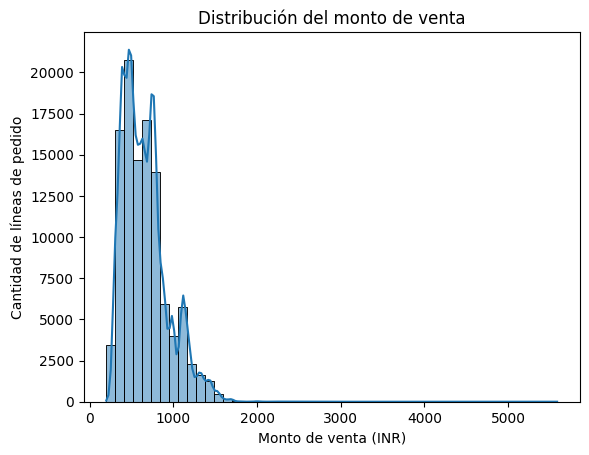

In [41]:
# histograma general de amount
sns.histplot(data=ventas, x='amount', bins=50, kde=True)
plt.xlabel('Monto de venta (INR)')
plt.ylabel('Cantidad de líneas de pedido')
plt.title('Distribución del monto de venta')
plt.show()


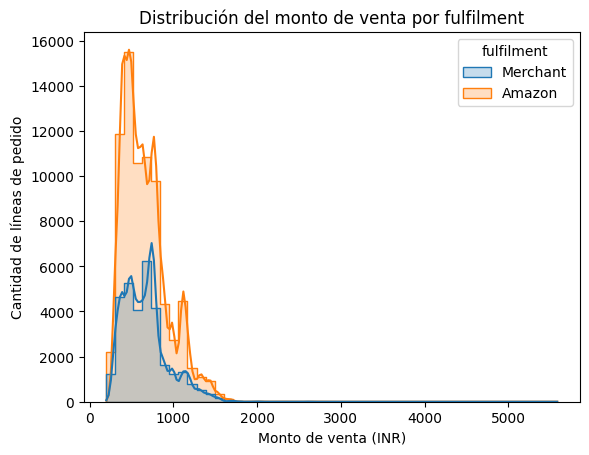

In [42]:
# histograma de amount por fulfilment
sns.histplot(data=ventas, x='amount', hue='fulfilment', bins=50, kde=True, element='step')
plt.xlabel('Monto de venta (INR)')
plt.ylabel('Cantidad de líneas de pedido')
plt.title('Distribución del monto de venta por fulfilment')
plt.show()


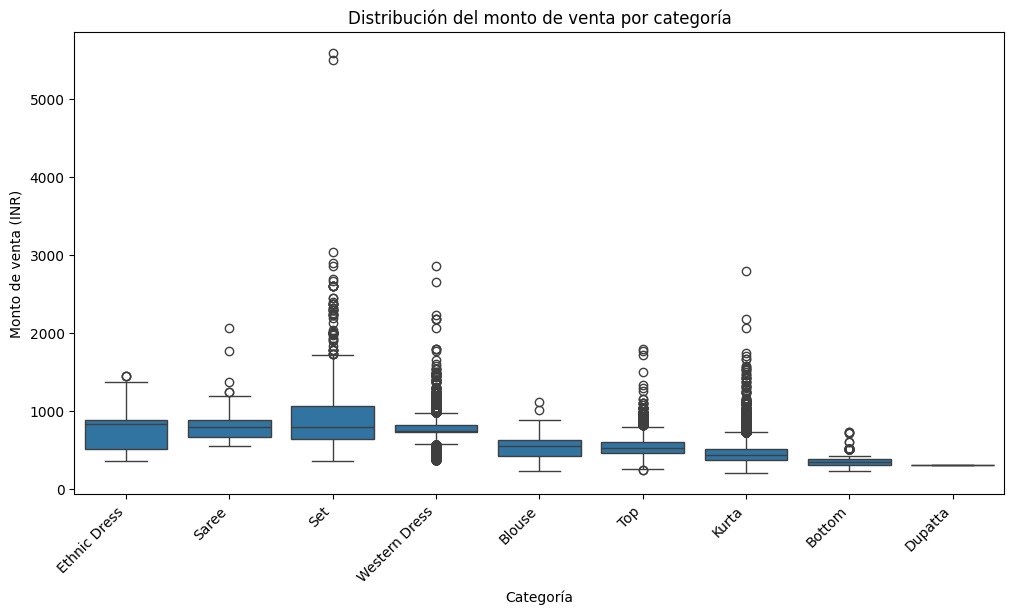

In [43]:
# boxplot de amount por categoría
plt.figure(figsize=(12, 6))
orden_categorias = ventas.groupby('category')['amount'].median().sort_values(ascending=False).index
sns.boxplot(data=ventas, x='category', y='amount', order=orden_categorias)
plt.xlabel('Categoría')
plt.ylabel('Monto de venta (INR)')
plt.title('Distribución del monto de venta por categoría')
plt.xticks(rotation=45, ha='right')
plt.show()


In [44]:
# outliers de amount con el método IQR
Q1 = ventas['amount'].quantile(0.25)
Q3 = ventas['amount'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR
outliers = ventas[(ventas['amount'] < limite_inferior) | (ventas['amount'] > limite_superior)]

print(f'límite inferior: {limite_inferior:.2f}')
print(f'límite superior: {limite_superior:.2f}')
print('cantidad de outliers:', len(outliers))
print('porcentaje de outliers:', round(len(outliers) / len(ventas) * 100, 2))


límite inferior: -34.50
límite superior: 1281.50
cantidad de outliers: 3492
porcentaje de outliers: 3.24


**Insights:**
El histograma general de `amount` muestra una distribución con sesgo claro hacia la derecha: la mayoría de las líneas se concentran entre 200 y 800 INR aproximadamente, con una cola larga de montos más altos. La comparación por fulfilment no muestra una diferencia marcada en la forma de la distribución entre Amazon y Merchant. Los boxplots por categoría confirman lo visto en 4.2: `Set` y `Saree` tienen las medianas más altas y `Bottom` y `Dupatta` las más bajas, con varias categorías mostrando bastantes puntos por encima del bigote superior.

Con el método IQR (Q1 = 459.0, Q3 = 788.0, IQR = 329.0), el límite inferior es -34.50 y el límite superior es 1,281.50 INR. Hay 3,492 outliers (3.24% de las ventas válidas), todos por encima del límite superior ya que el límite inferior es negativo y `amount` nunca es negativo. Decidimos conservar estos outliers: corresponden a precios reales de productos de mayor valor (probablemente sets o prendas premium), no a errores de captura, por lo que eliminarlos distorsionaría el análisis del ticket real del negocio.

### 4.4 Tendencia temporal

**Objetivo:**
Revisar la evolución de ventas y líneas de pedido por mes, la serie diaria de ventas, y comparar ventas y ticket por día de la semana y entre fin de semana y días hábiles.

            ventas_totales  lineas
mes_nombre                        
Abril           26234520.0   41006
Mayo            23952062.0   35344
Junio           21389367.0   31566


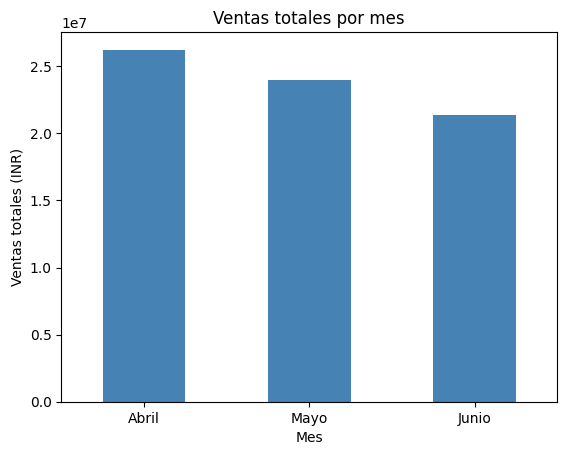

In [45]:
# ventas totales y líneas de pedido por mes
resumen_mes = ventas.groupby('mes_nombre').agg(ventas_totales=('amount', 'sum'), lineas=('amount', 'count')).reindex(['Abril', 'Mayo', 'Junio'])
print(resumen_mes)

resumen_mes['ventas_totales'].plot(kind='bar', color='steelblue')
plt.xlabel('Mes')
plt.ylabel('Ventas totales (INR)')
plt.title('Ventas totales por mes')
plt.xticks(rotation=0)
plt.show()


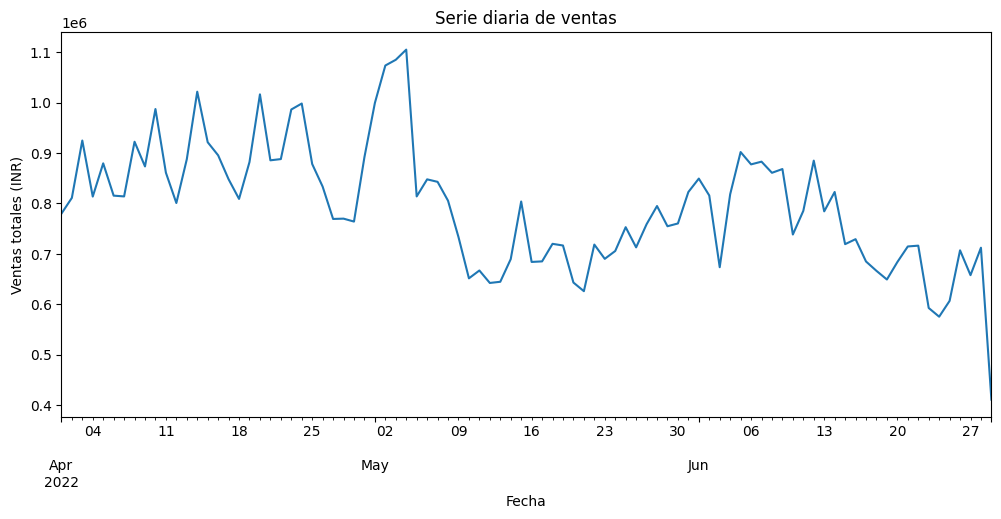

In [46]:
# serie diaria de ventas
serie_diaria = ventas.groupby('date')['amount'].sum()

plt.figure(figsize=(12, 5))
serie_diaria.plot()
plt.xlabel('Fecha')
plt.ylabel('Ventas totales (INR)')
plt.title('Serie diaria de ventas')
plt.show()


            ventas_totales  ticket_promedio
dia_semana                                 
Lunes           10307263.0       663.828363
Martes          10479268.0       663.748923
Miércoles       10290849.0       658.867341
Jueves           9383019.0       661.101881
Viernes          9842106.0       665.681840
Sábado          10288608.0       664.424152
Domingo         10984836.0       664.981900


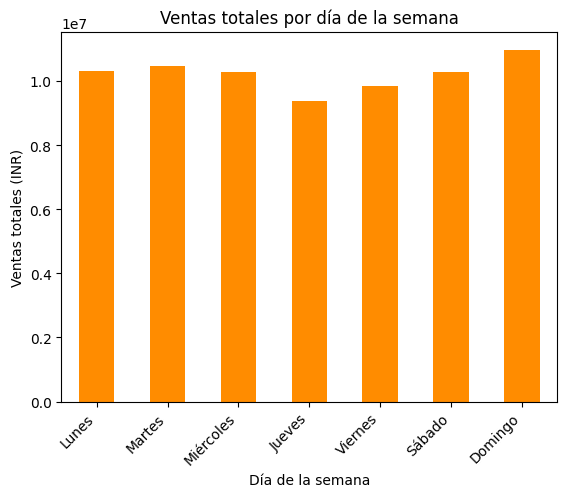

In [47]:
# ventas y ticket por día de la semana
orden_dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
resumen_dia = ventas.groupby('dia_semana').agg(ventas_totales=('amount', 'sum'), ticket_promedio=('amount', 'mean'))
resumen_dia = resumen_dia.reindex(orden_dias)
print(resumen_dia)

resumen_dia['ventas_totales'].plot(kind='bar', color='darkorange')
plt.xlabel('Día de la semana')
plt.ylabel('Ventas totales (INR)')
plt.title('Ventas totales por día de la semana')
plt.xticks(rotation=45, ha='right')
plt.show()


In [48]:
# ventas y ticket: fin de semana contra días hábiles
resumen_finde = ventas.groupby('fin_de_semana').agg(ventas_totales=('amount', 'sum'), lineas=('amount', 'count'), ticket_promedio=('amount', 'mean'))
print(resumen_finde)


               ventas_totales  lineas  ticket_promedio
fin_de_semana                                         
False              50302505.0   75912       662.642336
True               21273444.0   32004       664.712036


**Insights:**
Las ventas totales bajan mes a mes: 26,234,520 INR en abril (41,006 líneas), 23,952,062 INR en mayo (35,344 líneas) y 21,389,367 INR en junio (31,566 líneas), una tendencia decreciente tanto en monto como en volumen de líneas. La serie diaria de ventas muestra fluctuaciones día a día dentro de cada mes, consistente con esa tendencia general a la baja.

Por día de la semana, las ventas totales son más altas el domingo (10,984,836 INR) y el martes (10,479,268 INR), y más bajas el jueves (9,383,019 INR), aunque el ticket promedio por línea se mantiene muy estable entre 658.87 INR (miércoles) y 665.68 INR (viernes), sin diferencias grandes. Al comparar fin de semana contra días hábiles, el ticket promedio es prácticamente igual (664.71 INR en fin de semana contra 662.64 INR en días hábiles), aunque el fin de semana concentra menos líneas (32,004 contra 75,912 en días hábiles, lo esperado ya que son menos días).

### 4.5 Producto: categoría y talla

**Objetivo:**
Revisar ventas y participación por `category` y por `size`, ordenando las tallas de menor a mayor.

               ventas_totales  lineas  participacion_pct
category                                                
Set                35678039.0   41763              49.85
Kurta              19392329.0   41592              27.09
Western Dress      10204111.0   13132              14.26
Top                 4899555.0    9153               6.85
Ethnic Dress         732744.0     981               1.02
Blouse               418109.0     783               0.58
Bottom               135453.0     367               0.19
Saree                114694.0     142               0.16
Dupatta                 915.0       3               0.00


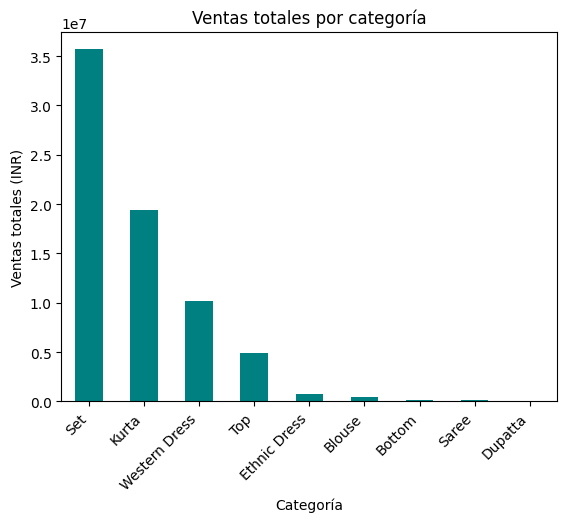

In [49]:
# ventas y participación por categoría
resumen_categoria = ventas.groupby('category')['amount'].agg(ventas_totales='sum', lineas='count')
resumen_categoria['participacion_pct'] = (resumen_categoria['ventas_totales'] / resumen_categoria['ventas_totales'].sum() * 100).round(2)
resumen_categoria = resumen_categoria.sort_values('ventas_totales', ascending=False)
print(resumen_categoria)

resumen_categoria['ventas_totales'].plot(kind='bar', color='teal')
plt.xlabel('Categoría')
plt.ylabel('Ventas totales (INR)')
plt.title('Ventas totales por categoría')
plt.xticks(rotation=45, ha='right')
plt.show()


      ventas_totales  lineas  participacion_pct
size                                           
XS         6325392.0    9153               8.84
S          9634171.0   14108              13.46
M         12591561.0   18845              17.59
L         12046791.0   18442              16.83
XL        11352958.0   17553              15.86
XXL        9759413.0   15263              13.64
3XL        8427796.0   12714              11.77
4XL         309571.0     373               0.43
5XL         398239.0     486               0.56
6XL         542031.0     655               0.76
Free        188026.0     324               0.26


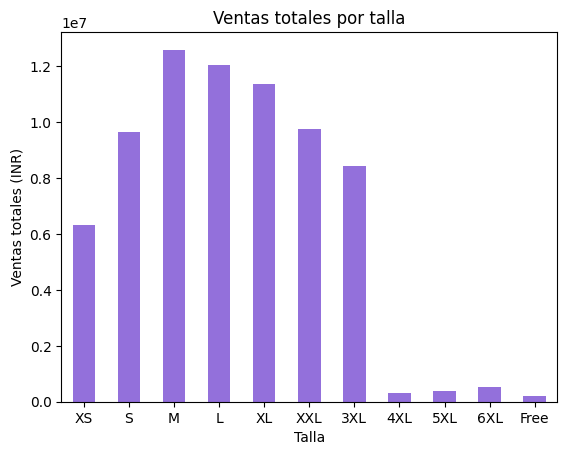

In [50]:
# ventas y participación por talla
orden_tallas = ['XS', 'S', 'M', 'L', 'XL', 'XXL', '3XL', '4XL', '5XL', '6XL', 'Free']
resumen_talla = ventas.groupby('size')['amount'].agg(ventas_totales='sum', lineas='count')
resumen_talla['participacion_pct'] = (resumen_talla['ventas_totales'] / resumen_talla['ventas_totales'].sum() * 100).round(2)
resumen_talla = resumen_talla.reindex([t for t in orden_tallas if t in resumen_talla.index])
print(resumen_talla)

resumen_talla['ventas_totales'].plot(kind='bar', color='mediumpurple')
plt.xlabel('Talla')
plt.ylabel('Ventas totales (INR)')
plt.title('Ventas totales por talla')
plt.xticks(rotation=0)
plt.show()


**Insights:**
Por categoría, `Set` domina las ventas con 35,678,039 INR (49.85% del total) y 41,763 líneas, seguida de `Kurta` con 19,392,329 INR (27.09%) y 41,592 líneas. `Western Dress` aporta 14.26% y `Top` 6.85%; el resto de categorías (`Ethnic Dress`, `Blouse`, `Bottom`, `Saree`, `Dupatta`) suman apenas 1.95% del total combinado. Es decir, `Set` y `Kurta` concentran casi el 77% de las ventas totales.

Por talla, la distribución es más pareja entre las tallas centrales: `M` tiene la mayor participación (17.59%, 12,591,561 INR), seguida de `L` (16.83%) y `XL` (15.86%). Las tallas extremas (`4XL`, `5XL`, `6XL`, `Free`) juntas apenas suman 2.01% de las ventas totales, lo que refleja una demanda concentrada en tallas estándar de S a 3XL.

### 4.6 Geografía

**Objetivo:**
Identificar los 10 estados con más ventas y revisar su tasa de cancelación, para ver si los estados más grandes en volumen también concentran más o menos cancelaciones.

                ventas_totales  tasa_cancelacion_pct
ship_state                                          
MAHARASHTRA         12209675.0             13.325838
KARNATAKA            9637606.0             12.953008
TELANGANA            6286590.0             14.405582
UTTAR PRADESH        6175144.0             15.097005
TAMIL NADU           5946144.0             13.889615
DELHI                4043774.0             13.100313
KERALA               3373793.0             17.825095
WEST BENGAL          3198240.0             14.816683
ANDHRA PRADESH       2878585.0             16.442396
HARYANA              2651293.0             12.752439


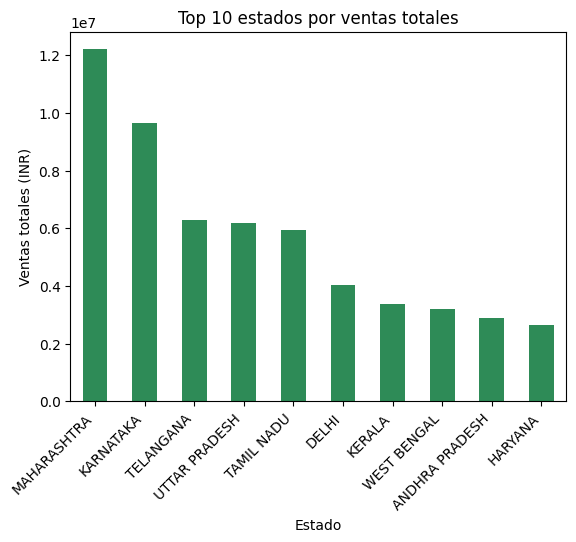

In [51]:
# top 10 estados por ventas y su tasa de cancelación
top_estados = ventas.groupby('ship_state')['amount'].sum().sort_values(ascending=False).head(10)
tasa_cancelacion_estado = df[df['ship_state'].isin(top_estados.index)].groupby('ship_state')['cancelado'].mean() * 100

resumen_geo = pd.DataFrame({'ventas_totales': top_estados, 'tasa_cancelacion_pct': tasa_cancelacion_estado.reindex(top_estados.index)})
print(resumen_geo)

resumen_geo['ventas_totales'].plot(kind='bar', color='seagreen')
plt.xlabel('Estado')
plt.ylabel('Ventas totales (INR)')
plt.title('Top 10 estados por ventas totales')
plt.xticks(rotation=45, ha='right')
plt.show()


**Insights:**
`Maharashtra` es el estado con más ventas (12,209,675 INR), seguido de `Karnataka` (9,637,606 INR) y `Telangana` (6,286,590 INR). En cuanto a tasa de cancelación, no hay una relación clara con el volumen de ventas: `Kerala` tiene la tasa de cancelación más alta del top 10 (17.83%) a pesar de tener el séptimo lugar en ventas, mientras que `Haryana` (último lugar del top 10 en ventas) tiene la tasa más baja (12.75%). Los dos estados con más ventas, `Maharashtra` y `Karnataka`, tienen tasas de cancelación relativamente moderadas (13.33% y 12.95% respectivamente), cercanas al promedio global de 14.22%.

### 4.7 Tasas de cancelación por factor

**Objetivo:**
Revisar cómo se distribuye `estatus_agrupado` (y la tasa de `cancelado`) según fulfilment, nivel de servicio de envío, promoción, categoría, tipo de cliente (b2b) y mes, con tablas cruzadas normalizadas por fila y gráficas. Además, revisar la relación entre fulfilment y ship_service_level, ya que están casi confundidos.

In [52]:
# relación entre fulfilment y ship_service_level
tabla_fulf_servicio = pd.crosstab(df['fulfilment'], df['ship_service_level'])
print(tabla_fulf_servicio)


ship_service_level  Expedited  Standard
fulfilment                             
Amazon                  88461      1083
Merchant                    0     39254


Como se observa en la tabla anterior, `fulfilment` y `ship_service_level` están casi confundidos: los pedidos Merchant son 100% Standard, mientras que los pedidos Amazon son casi todos Expedited, con muy pocos en Standard. Esto significa que ambos factores se mueven casi juntos y es difícil separar el efecto de uno del otro con estadística descriptiva simple; el Paso 5 tratará esta confusión con pruebas formales.

estatus_agrupado  Cancelado  Devuelto    Enviado  Incidencia  Pendiente
fulfilment                                                             
Amazon            12.793710  0.000000  86.742830    0.000000   0.463459
Merchant          17.463188  5.370153  75.816477    0.015285   1.334896


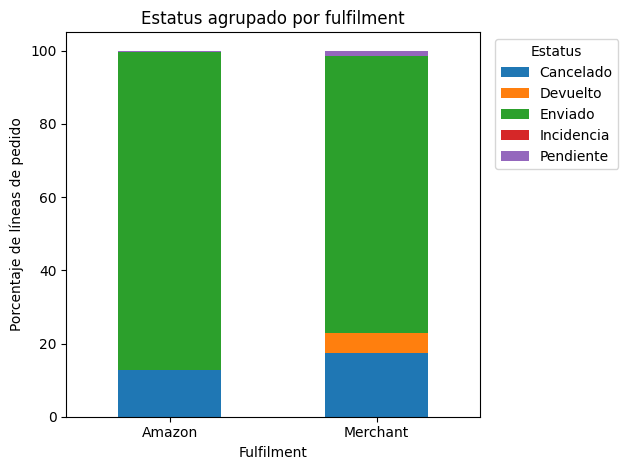

In [53]:
# tasa de cancelación por fulfilment
tabla_fulfilment = pd.crosstab(df['fulfilment'], df['estatus_agrupado'], normalize='index') * 100
print(tabla_fulfilment)

tabla_fulfilment.plot(kind='bar', stacked=True)
plt.xlabel('Fulfilment')
plt.ylabel('Porcentaje de líneas de pedido')
plt.title('Estatus agrupado por fulfilment')
plt.legend(title='Estatus', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


estatus_agrupado    Cancelado  Devuelto    Enviado  Incidencia  Pendiente
ship_service_level                                                       
Expedited           12.896078  0.000000  86.637049    0.000000   0.466872
Standard            17.113320  5.225971  76.341820    0.014875   1.304014


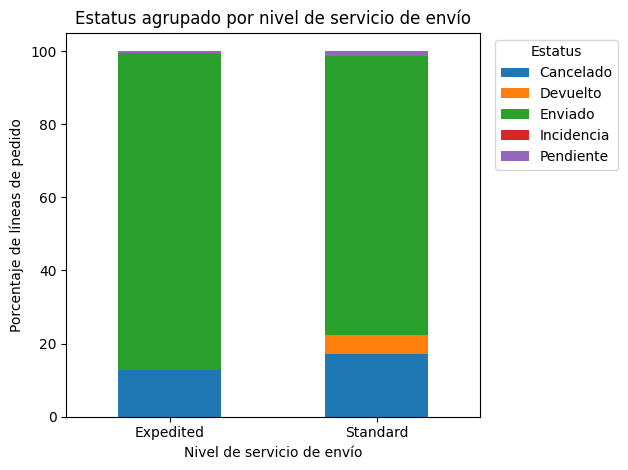

In [54]:
# tasa de cancelación por ship_service_level
tabla_servicio = pd.crosstab(df['ship_service_level'], df['estatus_agrupado'], normalize='index') * 100
print(tabla_servicio)

tabla_servicio.plot(kind='bar', stacked=True)
plt.xlabel('Nivel de servicio de envío')
plt.ylabel('Porcentaje de líneas de pedido')
plt.title('Estatus agrupado por nivel de servicio de envío')
plt.legend(title='Estatus', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


estatus_agrupado  Cancelado  Devuelto    Enviado  Incidencia  Pendiente
tiene_promocion                                                        
False             36.701434  0.008149  62.974658    0.000000   0.315759
True               0.370092  2.639568  95.999247    0.007527   0.983565


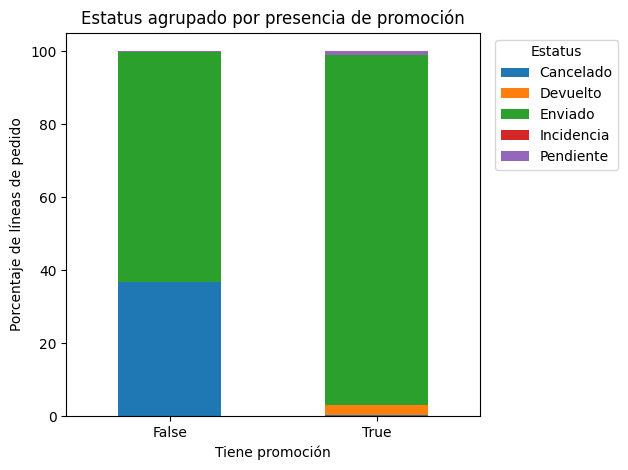

In [55]:
# tasa de cancelación por promoción
tabla_promocion = pd.crosstab(df['tiene_promocion'], df['estatus_agrupado'], normalize='index') * 100
print(tabla_promocion)

tabla_promocion.plot(kind='bar', stacked=True)
plt.xlabel('Tiene promoción')
plt.ylabel('Porcentaje de líneas de pedido')
plt.title('Estatus agrupado por presencia de promoción')
plt.legend(title='Estatus', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


tiene_promocion       False       True 
estatus_agrupado                       
Cancelado         98.388947    1.611053
Devuelto           0.189753   99.810247
Enviado           28.773945   71.226055
Incidencia         0.000000  100.000000
Pendiente         16.506922   83.493078


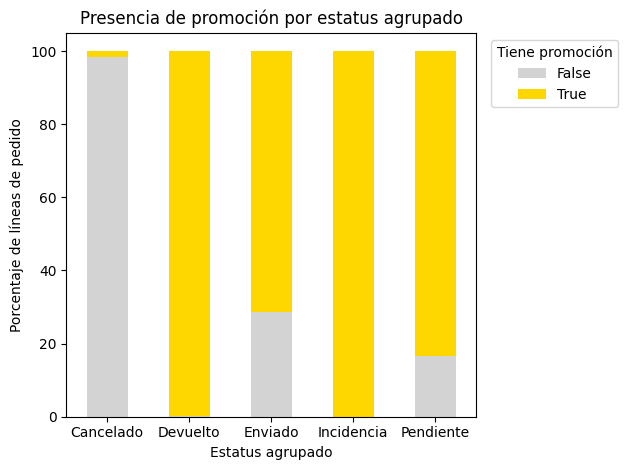

In [56]:
# crosstab de estatus_agrupado contra tiene_promocion, normalizado por fila
# esto revisa si tiene_promocion se captura por igual sin importar el resultado del pedido
tabla_estatus_promocion = pd.crosstab(df['estatus_agrupado'], df['tiene_promocion'], normalize='index') * 100
print(tabla_estatus_promocion)

tabla_estatus_promocion.plot(kind='bar', stacked=True, color=['lightgray', 'gold'])
plt.xlabel('Estatus agrupado')
plt.ylabel('Porcentaje de líneas de pedido')
plt.title('Presencia de promoción por estatus agrupado')
plt.legend(title='Tiene promoción', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


estatus_agrupado  Cancelado  Devuelto     Enviado  Incidencia  Pendiente
category                                                                
Blouse            12.540541  1.297297   85.729730    0.000000   0.432432
Bottom            13.636364  1.363636   84.318182    0.000000   0.681818
Dupatta            0.000000  0.000000  100.000000    0.000000   0.000000
Ethnic Dress      12.435233  1.381693   85.578584    0.000000   0.604491
Kurta             14.556810  1.510101   83.286477    0.004016   0.642596
Saree             12.804878  0.609756   86.585366    0.000000   0.000000
Set               14.591881  1.681074   83.006015    0.003984   0.717046
Top               12.022991  1.262602   86.017149    0.000000   0.697258
Western Dress     13.678910  2.214189   82.990123    0.012911   1.103867


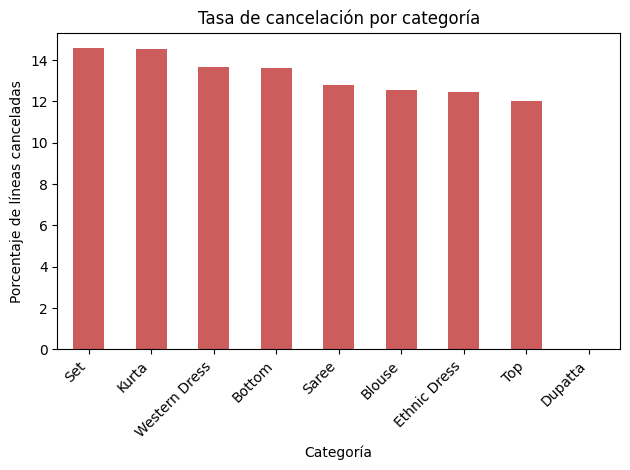

In [57]:
# tasa de cancelación por categoría
tabla_categoria = pd.crosstab(df['category'], df['estatus_agrupado'], normalize='index') * 100
print(tabla_categoria)

tabla_categoria['Cancelado'].sort_values(ascending=False).plot(kind='bar', color='indianred')
plt.xlabel('Categoría')
plt.ylabel('Porcentaje de líneas canceladas')
plt.title('Tasa de cancelación por categoría')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [58]:
# tasa de cancelación por b2b
tabla_b2b = pd.crosstab(df['b2b'], df['estatus_agrupado'], normalize='index') * 100
print(tabla_b2b)


estatus_agrupado  Cancelado  Devuelto    Enviado  Incidencia  Pendiente
b2b                                                                    
False             14.256568  1.640780  83.367077     0.00469   0.730886
True               8.381171  1.033295  90.126292     0.00000   0.459242


estatus_agrupado  Cancelado  Devuelto    Enviado  Incidencia  Pendiente
mes_nombre                                                             
Abril             14.541934  1.836340  83.615612    0.004076   0.002038
Mayo              13.971026  1.715156  84.287651    0.007137   0.019031
Junio             14.067806  1.289261  82.173175    0.002653   2.467105


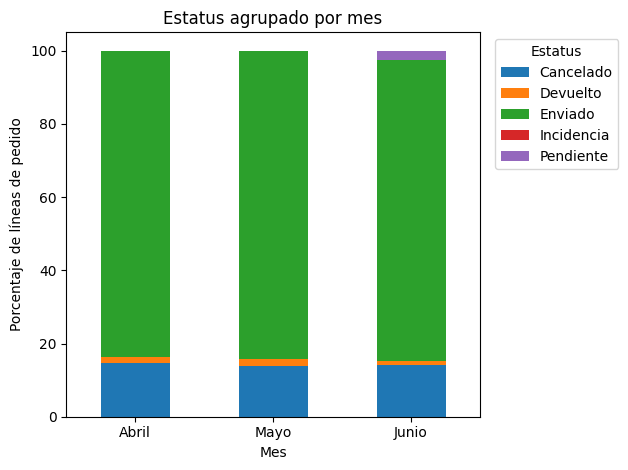

In [59]:
# tasa de cancelación por mes
tabla_mes = pd.crosstab(df['mes_nombre'], df['estatus_agrupado'], normalize='index') * 100
tabla_mes = tabla_mes.reindex(['Abril', 'Mayo', 'Junio'])
print(tabla_mes)

tabla_mes.plot(kind='bar', stacked=True)
plt.xlabel('Mes')
plt.ylabel('Porcentaje de líneas de pedido')
plt.title('Estatus agrupado por mes')
plt.legend(title='Estatus', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Insights:**
La tabla de `fulfilment` contra `ship_service_level` confirma la casi confusión entre ambos factores: los 39,254 pedidos Merchant son 100% Standard, mientras que de los 89,544 pedidos Amazon, 88,461 (98.79%) son Expedited y solo 1,083 (1.21%) son Standard. Esto hace muy difícil separar el efecto de fulfilment del efecto de ship_service_level con solo estadística descriptiva.

Los patrones de cancelación son consistentes entre ambos factores: Merchant tiene 17.46% de cancelación contra 12.79% en Amazon, y Standard tiene 17.11% contra 12.90% en Expedited, números muy cercanos entre sí (como era de esperarse dado que casi todo Merchant es Standard). Merchant también tiene un 5.37% de líneas `Devuelto`, contra 0% en Amazon, y un 1.33% `Pendiente` contra 0.46% en Amazon.

Por categoría, las tasas de cancelación son más parejas, entre 12.02% (`Top`) y 14.59% (`Set`), con `Dupatta` en 0% (solo 3 líneas). Por tipo de cliente, los pedidos B2B cancelan menos (8.38%) que los B2C (14.26%). Por mes, la tasa de cancelación se mantiene relativamente estable: 14.54% en abril, 13.97% en mayo y 14.07% en junio, aunque junio muestra un salto notable en `Pendiente` (2.47% contra 0.002% en abril y 0.019% en mayo), posiblemente por pedidos de fin de periodo que aún no se resuelven al cierre de los datos.

Sobre `tiene_promocion`, la tabla cruzada por estatus muestra una diferencia enorme: solo 0.37% de las líneas con promoción están canceladas, contra 36.70% de las líneas sin promoción (visto en la tabla de arriba). Pero al leer la tabla en la dirección inversa (`estatus_agrupado` contra `tiene_promocion`, normalizada por fila de estatus) se ve el problema: 98.39% de las líneas Canceladas no tiene `promotion_ids` capturado, contra solo 28.77% de las líneas Enviadas y apenas 0.19% de las Devueltas. Es decir, `promotion_ids` casi no se llena en pedidos cancelados, se llena casi siempre en pedidos que sí avanzan (Enviado, Devuelto, Incidencia, Pendiente). Esto es un patrón de captura ligado al resultado del pedido, no evidencia de que la promoción reduzca la cancelación. Tratamos esta relación como una limitación de calidad del dato, no como un hallazgo de negocio, y no la usamos para explicar la cancelación.

### 4.8 Promociones

**Objetivo:**
Revisar el porcentaje de líneas con promoción por fulfilment y por categoría, para detectar si las promociones se concentran en ciertos segmentos, lo que podría ser un factor de confusión al comparar el ticket entre esos segmentos.

fulfilment
Amazon      52.911418
Merchant    82.363581
Name: tiene_promocion, dtype: float64


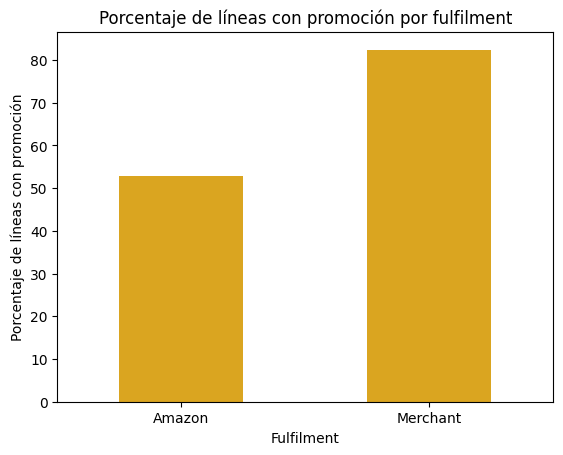

In [60]:
# porcentaje de líneas con promoción por fulfilment
pct_promo_fulfilment = df.groupby('fulfilment')['tiene_promocion'].mean() * 100
print(pct_promo_fulfilment)

pct_promo_fulfilment.plot(kind='bar', color='goldenrod')
plt.xlabel('Fulfilment')
plt.ylabel('Porcentaje de líneas con promoción')
plt.title('Porcentaje de líneas con promoción por fulfilment')
plt.xticks(rotation=0)
plt.show()


category
Dupatta          100.000000
Western Dress     71.635143
Saree             70.731707
Bottom            66.363636
Set               66.029957
Kurta             56.164906
Ethnic Dress      56.044905
Top               55.921982
Blouse            53.837838
Name: tiene_promocion, dtype: float64


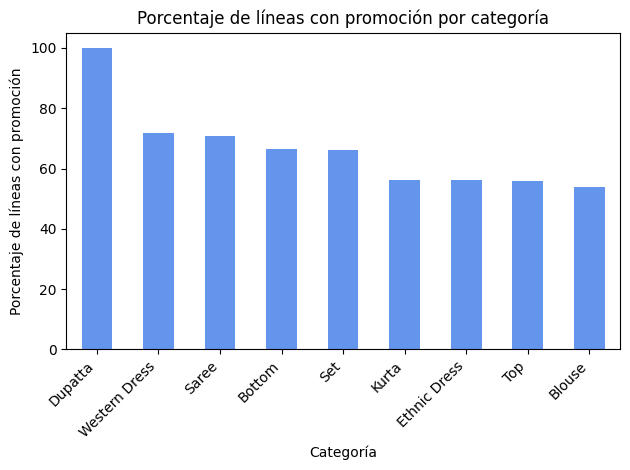

In [61]:
# porcentaje de líneas con promoción por categoría
pct_promo_categoria = (df.groupby('category')['tiene_promocion'].mean() * 100).sort_values(ascending=False)
print(pct_promo_categoria)

pct_promo_categoria.plot(kind='bar', color='cornflowerblue')
plt.xlabel('Categoría')
plt.ylabel('Porcentaje de líneas con promoción')
plt.title('Porcentaje de líneas con promoción por categoría')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Insights:**
El porcentaje de líneas con promoción es mucho mayor en Merchant (82.36%) que en Amazon (52.91%), una diferencia de casi 30 puntos porcentuales. Por categoría, `Dupatta` tiene 100% de promoción (aunque solo 3 líneas), seguida de `Western Dress` (71.64%) y `Saree` (70.73%); las categorías con menor presencia de promoción son `Blouse` (53.84%), `Top` (55.92%) y `Ethnic Dress` (56.04%).

Esto confirma que las promociones no se distribuyen parejo entre segmentos: se concentran fuertemente en Merchant y en ciertas categorías como `Western Dress` y `Saree`. En 4.2 vimos que, dentro de las ventas válidas, las líneas con promoción tienen un ticket promedio más alto (680.95 INR contra 615.89 INR sin promoción); esa comparación de ticket solo usa ventas válidas (no canceladas), así que no está contaminada por el patrón de captura de `promotion_ids` que describimos en 4.7. Sin embargo, como la presencia de promoción varía tanto entre fulfilment y categoría, sigue siendo un factor de confusión real para comparar el ticket entre esos segmentos: parte de la diferencia de ticket observada entre Amazon y Merchant, o entre categorías, podría deberse a la distinta mezcla de líneas con y sin promoción en cada segmento, no a un efecto directo del fulfilment o la categoría en sí. A diferencia del ticket, la relación entre promoción y cancelación no se puede interpretar de forma causal, como se explicó en 4.7.

### Observaciones del Paso 4

En este paso revisamos el comportamiento general de las ventas de Amazon India entre abril y junio de 2022. Las 128,798 líneas de pedido corresponden a 120,220 pedidos únicos, con ventas totales de 71,575,949 INR en ventas válidas, un ticket promedio de 663.26 INR (mediana 625.0 INR) y una tasa de cancelación global de 14.22%. La distribución del ticket tiene sesgo a la derecha, con 3,492 outliers (3.24%) según el método IQR que decidimos conservar por ser precios reales de producto.

En términos de producto, `Set` y `Kurta` concentran cerca del 77% de las ventas totales, y las tallas centrales (S a 3XL) dominan sobre las tallas extremas. En términos temporales, las ventas bajan de 26.2 millones de INR en abril a 21.4 millones en junio, mientras que el ticket promedio se mantiene estable entre días de la semana y entre fin de semana y días hábiles. Geográficamente, `Maharashtra` y `Karnataka` concentran las mayores ventas, sin que el volumen de ventas por estado se relacione claramente con su tasa de cancelación.

Un hallazgo importante es la casi confusión entre `fulfilment` y `ship_service_level` (Merchant es 100% Standard, Amazon es 98.79% Expedited), que hace difícil separar el efecto de uno del otro con estadística descriptiva simple. Otro hallazgo es la concentración desigual de promociones por fulfilment (82.36% en Merchant contra 52.91% en Amazon) y por categoría, que es un factor de confusión real al comparar el ticket promedio entre segmentos.

Es importante aclarar una limitación del dataset: encontramos que solo 0.37% de las líneas con promoción están canceladas, contra 36.70% de las líneas sin promoción, pero esta diferencia no se puede leer como que la promoción reduzca la cancelación. Al revisar la tabla cruzada en la dirección inversa, el 98.39% de las líneas Canceladas no tiene `promotion_ids` capturado, contra solo 28.77% de las Enviadas y 0.19% de las Devueltas. Esto indica que `promotion_ids` se llena de forma sistemática después de que se conoce el resultado del pedido (se registra casi siempre que se envía o incide, casi nunca cuando se cancela), es decir, es una variable que depende del desenlace y no un factor que lo explique. Por eso la relación entre promoción y cancelación queda documentada como limitación de captura del dataset, y no se usa como evidencia de un efecto de negocio; el Paso 5 debe evitar tratar `tiene_promocion` como predictor de la cancelación por esta misma razón.

Estos hallazgos descriptivos, junto con la casi confusión entre fulfilment y ship_service_level, dan la base para las pruebas de hipótesis formales que se abordan en el Paso 5, que deberán considerar estos factores de confusión y limitaciones al interpretar cualquier diferencia en cancelación o en ticket promedio.

## Paso 5: Pruebas de hipótesis

### 5.1 Planteamiento

**Objetivo:** poner a prueba, de forma estadística, las preguntas de negocio más relevantes que surgieron en la exploración (Pasos 3 y 4) sobre las ventas de Amazon India de abril a junio de 2022. Se trabaja con un nivel de significancia alfa = 0.05 en todas las pruebas. El análisis de ticket (monto por línea de pedido) se hace siempre sobre `ventas`, el subconjunto de `venta_valida` (pedidos no cancelados, con `amount` no nulo y mayor a 0), tal como se definio en el Paso 3.

Preguntas que se van a responder en este paso:

- H1: la cancelación, es independiente del tipo de fulfilment (Amazon vs Merchant)?
- H2: el ticket promedio difiere entre pedidos con promoción y sin promoción? La cancelación está asociada con tener promoción?
- H3: el ticket promedio difiere entre categorías de producto?
- H4: la cancelación está asociada con el nivel de servicio de envío (Expedited vs Standard)?
- H5: el ticket promedio difiere entre meses y entre fin de semana y días hábiles?
- H6: el ticket promedio difiere entre pedidos B2B y B2C? La cancelación está asociada con ser B2B?

**Criterio de pruebas:** para comparar variables categoricas se usa chi cuadrado de independencia junto con la V de Cramér como tamaño de efecto, y cuando aplica, residuos estandarizados ajustados para ver que celdas explican la asociación. Para comparar el ticket promedio entre dos grupos se usa la prueba t de Welch (no asume varianzas iguales), con intervalo de confianza del 95% para la diferencia de medias y la d de Cohen como tamaño de efecto; se agrega la prueba de Mann-Whitney U como robustez, porque `amount` tiene una distribución con sesgo a la derecha. Para comparar el ticket promedio entre tres o más grupos se usa el ANOVA de Welch, con eta cuadrada como tamaño de efecto, y la prueba de Kruskal-Wallis como robustez. Antes de cada prueba de medias se revisa normalidad con la prueba de D'Agostino Pearson (con n tan grande, Shapiro no es adecuado) y homogeneidad de varianzas con Levene.

Con un tamaño de muestra tan grande (128,798 líneas de pedido, 107,916 ventas validas), casi cualquier diferencia resulta estadísticamente significativa. Por eso en cada prueba se pone el enfasis en el tamaño del efecto y en la diferencia práctica, en rupias o en puntos porcentuales, más que en el p valor por si solo.

Importante: todas las pruebas de este paso muestran asociación, no causalidad. Un resultado significativo no implica que una variable cause la otra; en varios casos (fulfilment, nivel de servicio, promociones) las variables estan fuertemente relacionadas entre sí, lo que se revisa explícitamente antes de interpretar cada prueba.

In [62]:
# alfa de trabajo y subconjunto de ventas validas para el análisis de ticket
alfa = 0.05
ventas = df[df['venta_valida']].copy()
print('líneas de pedido totales:', len(df))
print('ventas validas:', len(ventas))

líneas de pedido totales: 128798
ventas validas: 107916


**Funciones auxiliares**

Se definen aquí las funciones que se van a reutilizar en varias hipótesis de este paso.

In [63]:
# función auxiliar: chi cuadrado de independencia junto con la V de Cramér
def prueba_chi2_cramer(tabla):
    chi2, p, gl, esperado = stats.chi2_contingency(tabla)
    n = tabla.values.sum()
    filas, columnas = tabla.shape
    v = np.sqrt((chi2 / n) / (min(filas - 1, columnas - 1)))
    return chi2, p, gl, esperado, v

In [64]:
# función auxiliar para ANOVA de Welch, cuando las varianzas no son homogeneas
def anova_welch(grupos):
    k = len(grupos)
    ni = np.array([len(g) for g in grupos])
    mi = np.array([g.mean() for g in grupos])
    vi = np.array([g.var(ddof=1) for g in grupos])
    wi = ni / vi
    media_ponderada = np.sum(wi * mi) / np.sum(wi)
    numerador = np.sum(wi * (mi - media_ponderada) ** 2) / (k - 1)
    termino = np.sum((1 - wi / np.sum(wi)) ** 2 / (ni - 1))
    denominador = 1 + (2 * (k - 2) / (k ** 2 - 1)) * termino
    F = numerador / denominador
    gl1 = k - 1
    gl2 = (k ** 2 - 1) / (3 * termino)
    p = stats.f.sf(F, gl1, gl2)  # cola derecha, evita que p se redondee a 0
    return F, gl1, gl2, p

In [65]:
# función auxiliar: prueba t de Welch con intervalo de confianza y d de Cohen
def prueba_t_welch(grupo_a, grupo_b):
    resultado = stats.ttest_ind(grupo_a, grupo_b, equal_var=False)
    ic = resultado.confidence_interval(confidence_level=0.95)
    diferencia = grupo_a.mean() - grupo_b.mean()
    d = diferencia / np.sqrt((grupo_a.var(ddof=1) + grupo_b.var(ddof=1)) / 2)
    return resultado.statistic, resultado.df, resultado.pvalue, diferencia, ic.low, ic.high, d

In [66]:
# función auxiliar: intervalo de confianza del 95% para una diferencia de proporciones
def ic_diferencia_proporciones(exitos_1, n_1, exitos_2, n_2, alfa=0.05):
    p1 = exitos_1 / n_1
    p2 = exitos_2 / n_2
    diferencia = p1 - p2
    error_estandar = np.sqrt(p1 * (1 - p1) / n_1 + p2 * (1 - p2) / n_2)
    z = stats.norm.ppf(1 - alfa / 2)
    return diferencia, diferencia - z * error_estandar, diferencia + z * error_estandar

### 5.2 H1: fulfilment y cancelación

**Objetivo:** evaluar si el tipo de fulfilment (`Amazon` o `Merchant`) y la cancelación del pedido son independientes, con una prueba chi cuadrado de independencia.

- H0: el fulfilment y la cancelación son independientes.
- H1: el fulfilment y la cancelación estan asociados.

In [67]:
# tabla de contingencia entre fulfilment y cancelado
tabla_h1 = pd.crosstab(df['fulfilment'], df['cancelado'])
tabla_h1

cancelado,False,True
fulfilment,,
Amazon,78088,11456
Merchant,32399,6855


In [68]:
# chi cuadrado de independencia y V de Cramér
chi2_h1, p_h1, gl_h1, esperado_h1, v_h1 = prueba_chi2_cramer(tabla_h1)

print(f'chi2 = {chi2_h1:.2f}, gl = {gl_h1}, p = {p_h1:.3e}')
print('frecuencia esperada mínima:', round(esperado_h1.min(), 2))
print('V de Cramér:', round(v_h1, 4))

chi2 = 487.53, gl = 1, p = 4.910e-108
frecuencia esperada mínima: 5580.68
V de Cramér: 0.0615


Insights:

La frecuencia esperada mínima es de 5,580.68, muy por encima del umbral de 5, así que se cumple el supuesto para usar chi cuadrado.

chi2 = 487.53, con gl = 1 y p = 4.91e-108, un valor mucho menor que alfa = 0.05. Se rechaza H0: la cancelación sí está asociada con el tipo de fulfilment.

La V de Cramér es 0.0615, un tamaño de efecto pequeño según los umbrales convencionales (menor a 0.1). El resultado es estadísticamente significativo pero de magnitud modesta, algo esperable con un tamaño de muestra de 128,798 líneas de pedido.

In [69]:
# residuos estandarizados ajustados, para ver que celdas explican la asociación
n_h1 = tabla_h1.values.sum()
suma_filas_h1 = tabla_h1.sum(axis=1).values.reshape(-1, 1)
suma_columnas_h1 = tabla_h1.sum(axis=0).values.reshape(1, -1)
residuos_h1 = (tabla_h1.values - esperado_h1) / np.sqrt(
    esperado_h1 * (1 - suma_filas_h1 / n_h1) * (1 - suma_columnas_h1 / n_h1)
)
residuos_h1 = pd.DataFrame(residuos_h1, index=tabla_h1.index, columns=tabla_h1.columns)
residuos_h1.round(2)

cancelado,False,True
fulfilment,,
Amazon,22.09,-22.09
Merchant,-22.09,22.09


Insights:

Usando el criterio habitual de considerar significativa una celda cuando el residuo ajustado supera 1.96 en valor absoluto, las cuatro celdas superan ese umbral con holgura: Amazon tiene menos cancelaciones de las esperadas y Merchant tiene más cancelaciones de las esperadas bajo independencia. Esto confirma que la asociación no es un artefacto de una sola celda, sino un patron consistente en las dos categorías de fulfilment.

In [70]:
# diferencia de tasas de cancelación en puntos porcentuales, con intervalo de confianza del 95%
cancel_amazon = tabla_h1.loc['Amazon', True]
n_amazon = tabla_h1.loc['Amazon'].sum()
cancel_merchant = tabla_h1.loc['Merchant', True]
n_merchant = tabla_h1.loc['Merchant'].sum()

tasa_amazon = cancel_amazon / n_amazon
tasa_merchant = cancel_merchant / n_merchant
diferencia_h1, ic_low_h1, ic_high_h1 = ic_diferencia_proporciones(cancel_merchant, n_merchant, cancel_amazon, n_amazon)

print(f'tasa de cancelación Amazon: {tasa_amazon * 100:.2f}% (n = {n_amazon})')
print(f'tasa de cancelación Merchant: {tasa_merchant * 100:.2f}% (n = {n_merchant})')
print(f'diferencia (Merchant menos Amazon) = {diferencia_h1 * 100:.2f} puntos porcentuales, IC 95% = ({ic_low_h1 * 100:.2f}, {ic_high_h1 * 100:.2f})')

tasa de cancelación Amazon: 12.79% (n = 89544)
tasa de cancelación Merchant: 17.46% (n = 39254)
diferencia (Merchant menos Amazon) = 4.67 puntos porcentuales, IC 95% = (4.23, 5.10)


Insights:

La tasa de cancelación es de 12.79% en Amazon (11,456 de 89,544 líneas) y de 17.46% en Merchant (6,855 de 39,254 líneas). La diferencia es de 4.67 puntos porcentuales a favor de Amazon, con un intervalo de confianza del 95% entre 4.23 y 5.10 puntos, que no cruza el cero.

Lectura de negocio: los pedidos que Amazon cumple directamente (fulfilment by Amazon) se cancelan con menos frecuencia que los que cumple el propio vendedor (Merchant). La diferencia es real y consistente, aunque de tamaño modesto (V de Cramér pequeña); en términos de volumen, si Merchant tuviera la misma tasa de cancelación que Amazon, se hubieran evitado del orden de 1,833 cancelaciones (4.67% de 39,254 líneas) en el trimestre.

### 5.3 H2: promociones

**Objetivo:** evaluar (a) si el ticket promedio difiere entre pedidos con promoción y sin promoción, y (b) si la cancelación está asociada con tener promoción. Antes de interpretar cualquiera de las dos pruebas se revisa si la promoción se concentra de forma distinta según el fulfilment, porque eso podria confundir el resultado.

In [71]:
# la promoción, se reparte igual entre fulfilment?
tabla_promo_fulfilment = pd.crosstab(df['fulfilment'], df['tiene_promocion'], normalize='index') * 100
tabla_promo_fulfilment.round(2)

tiene_promocion,False,True
fulfilment,,
Amazon,47.09,52.91
Merchant,17.64,82.36


Insights:

No. El 52.91% de las líneas de Amazon tienen promoción, contra el 82.36% de las líneas de Merchant. Esto es una confusión fuerte entre `tiene_promocion` y `fulfilment`: los pedidos Merchant traen promoción con mucha más frecuencia que los de Amazon, así que cualquier prueba que compare pedidos con y sin promoción está comparando, en buena medida, Amazon contra Merchant. Se toma esto en cuenta al interpretar las pruebas que siguen, y se repite la parte del ticket estratificando por fulfilment.

**5.3.a Ticket: con promoción contra sin promoción**

- H0: el ticket promedio es igual entre pedidos con promoción y sin promoción.
- H1: el ticket promedio es distinto entre pedidos con promoción y sin promoción.

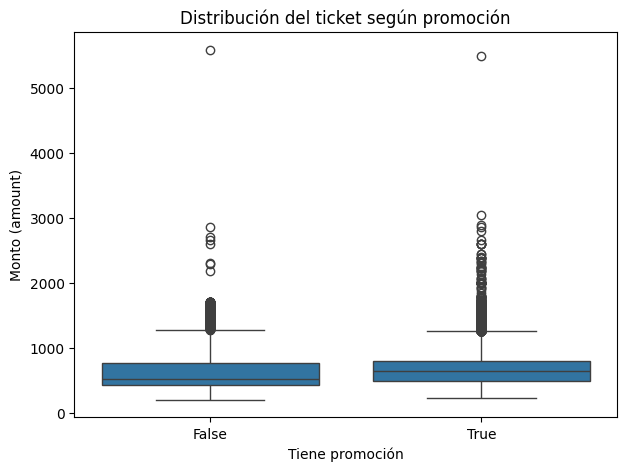

In [72]:
# boxplot de apoyo, ticket según promoción
plt.figure(figsize=(7, 5))
sns.boxplot(data=ventas, x='tiene_promocion', y='amount')
plt.xlabel('Tiene promoción')
plt.ylabel('Monto (amount)')
plt.title('Distribución del ticket según promoción')
plt.show()

con promoción: n = 78564, estadístico = 15327.63, p = 0.000e+00
sin promoción: n = 29352, estadístico = 9502.12, p = 0.000e+00


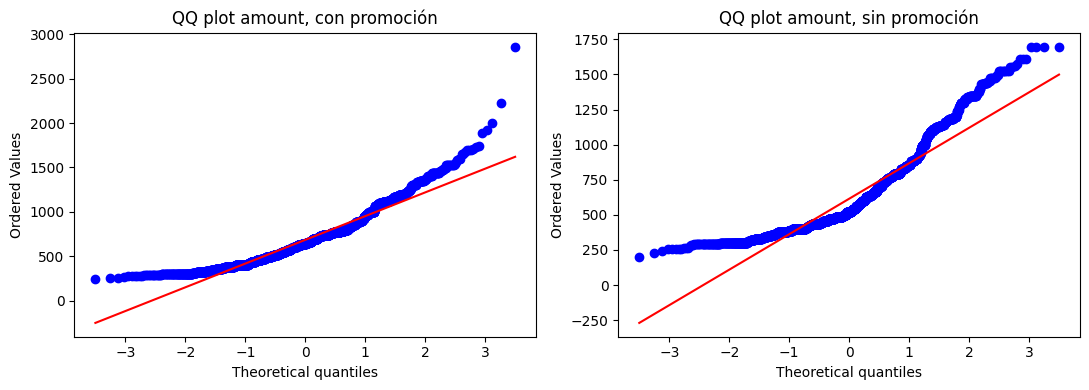

In [73]:
# verificación de normalidad con D'Agostino Pearson, con n grande Shapiro no es adecuado
grupo_promo = ventas.loc[ventas['tiene_promocion'], 'amount']
grupo_sin_promo = ventas.loc[~ventas['tiene_promocion'], 'amount']

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nombre, muestra in zip(axes, ['con promoción', 'sin promoción'], [grupo_promo, grupo_sin_promo]):
    estad, p_norm = stats.normaltest(muestra)
    print(f'{nombre}: n = {len(muestra)}, estadístico = {estad:.2f}, p = {p_norm:.3e}')
    muestra_qq = muestra.sample(min(3000, len(muestra)), random_state=42)
    stats.probplot(muestra_qq, dist='norm', plot=ax)
    ax.set_title(f'QQ plot amount, {nombre}')
plt.tight_layout()
plt.show()

Insights:

En los dos grupos p es mucho menor que alfa, así que se rechaza la normalidad según la prueba de D'Agostino Pearson, y los QQ plot muestran que `amount` se aleja de la recta teórica, con sesgo hacia la derecha (hay un piso natural en el monto y una cola de pedidos caros). Sin embargo, los tamaños de muestra son grandes (78,564 y 29,352 observaciones). Por el teorema del límite central, la distribución muestral de la media se aproxima a una normal aunque los datos originales no lo sean, así que la prueba t de Welch sigue siendo razonable; además se agrega Mann-Whitney U como robustez, porque no depende de normalidad.

In [74]:
# homogeneidad de varianzas con Levene
lev_stat_h2, lev_p_h2 = stats.levene(grupo_promo, grupo_sin_promo)
print(f'Levene: estadístico = {lev_stat_h2:.2f}, p = {lev_p_h2:.3e}')

Levene: estadístico = 21.40, p = 3.735e-06


Insights:

Levene: estadístico = 21.40, p = 3.73e-06, menor que alfa. No se cumple la homogeneidad de varianzas, así que se usa la prueba t de Welch, que no asume varianzas iguales.

In [75]:
# prueba t de Welch, ticket con promoción contra sin promoción
t_h2, gl_h2, p_h2, dif_h2, ic_low_h2, ic_high_h2, d_h2 = prueba_t_welch(grupo_promo, grupo_sin_promo)
print(f't = {t_h2:.2f}, gl = {gl_h2:.1f}, p = {p_h2:.3e}')
print(f'diferencia de medias = {dif_h2:.2f}, IC 95% = ({ic_low_h2:.2f}, {ic_high_h2:.2f})')
print(f'd de Cohen = {d_h2:.3f}')

# robustez: Mann-Whitney U
mw_h2 = stats.mannwhitneyu(grupo_promo, grupo_sin_promo)
print(f'Mann-Whitney U = {mw_h2.statistic:.0f}, p = {mw_h2.pvalue:.3e}')

print(ventas.groupby('tiene_promocion')['amount'].agg(['mean', 'median', 'std']))

t = 35.53, gl = 52734.5, p = 2.449e-273
diferencia de medias = 65.07, IC 95% = (61.48, 68.65)
d de Cohen = 0.243
Mann-Whitney U = 1351793370, p = 0.000e+00
                       mean  median         std
tiene_promocion                                
False            615.888117   518.0  267.502497
True             680.953121   641.0  268.073014


Insights:

t = 35.53, gl = 52,734.5, p = 2.45e-273, mucho menor que alfa. Se rechaza H0: el ticket promedio sí difiere entre pedidos con y sin promoción. Mann-Whitney U confirma la diferencia (p prácticamente 0), así que la conclusión no depende del supuesto de normalidad.

La diferencia de medias es de 65.07 rupias (680.95 con promoción contra 615.89 sin promoción), con un intervalo de confianza del 95% entre 61.48 y 68.65 rupias. La d de Cohen es 0.243, un tamaño de efecto pequeño según los umbrales convencionales (0.2 pequeño, 0.5 mediano, 0.8 grande).

Lectura de negocio: los pedidos con promoción tienen un ticket algo mayor, pero la diferencia es chica en términos prácticos (65 rupias sobre un ticket promedio de 663 rupias, cerca de 10%). Además, como se vio arriba, la promoción está fuertemente concentrada en Merchant, así que antes de leer esto como "las promociones suben el ticket" conviene revisarlo dentro de cada fulfilment.

In [76]:
# misma prueba, más ilustración, estratificada por fulfilment para separar el efecto de la promoción del efecto del fulfilment
for fulfil in ['Amazon', 'Merchant']:
    sub = ventas[ventas['fulfilment'] == fulfil]
    g_promo_e = sub.loc[sub['tiene_promocion'], 'amount']
    g_sin_e = sub.loc[~sub['tiene_promocion'], 'amount']
    print(f'{fulfil}: n con promoción = {len(g_promo_e)}, n sin promoción = {len(g_sin_e)}')
    if len(g_promo_e) > 1 and len(g_sin_e) > 1:
        t_e, gl_e, p_e, dif_e, ic_low_e, ic_high_e, d_e = prueba_t_welch(g_promo_e, g_sin_e)
        print(f'  t = {t_e:.2f}, gl = {gl_e:.1f}, p = {p_e:.3e}, diferencia = {dif_e:.2f}, '
              f'IC 95% = ({ic_low_e:.2f}, {ic_high_e:.2f}), d de Cohen = {d_e:.3f}')

Amazon: n con promoción = 47012, n sin promoción = 29332
  t = 37.27, gl = 62221.2, p = 1.066e-300, diferencia = 74.18, IC 95% = (70.28, 78.08), d de Cohen = 0.277
Merchant: n con promoción = 31552, n sin promoción = 20
  t = 0.84, gl = 19.0, p = 4.104e-01, diferencia = 47.18, IC 95% = (-70.13, 164.49), d de Cohen = 0.182


Insights:

Dentro de Amazon: n = 47,012 con promoción y n = 29,332 sin promoción, t = 37.27, p = 1.07e-300, diferencia de 74.18 rupias (IC 95% de 70.28 a 78.08), d de Cohen = 0.277 (pequeño). El efecto se mantiene, e incluso es un poco mayor que en la prueba sin estratificar.

Dentro de Merchant: n = 31,552 con promoción contra apenas n = 20 sin promoción, t = 0.84, p = 0.410, no se rechaza H0. Con solo 20 pedidos Merchant sin promoción, esta comparación no tiene poder estadístico suficiente para sacar conclusiones.

Conclusión: la diferencia de ticket asociada a la promoción se sostiene y es de magnitud similar dentro de Amazon, donde sí hay una cantidad razonable de pedidos en ambos grupos. La confusión con fulfilment no explica todo el efecto, pero el tamaño de efecto sigue siendo pequeño en cualquier versión de la prueba.

**5.3.b Cancelación y promoción**

- H0: tener promoción y la cancelación del pedido son independientes.
- H1: tener promoción y la cancelación del pedido estan asociados.

Antes de correr cualquier prueba, conviene revisar como se captura `promotion_ids` según el resultado final del pedido (`estatus_agrupado`), porque hay motivos para sospechar que no es una variable capturada de forma pareja en todos los estatus.

In [77]:
# tiene_promocion según estatus_agrupado, normalizado por fila
tabla_diagnostico = pd.crosstab(df['estatus_agrupado'], df['tiene_promocion'], normalize='index') * 100
tabla_diagnostico.round(2)

tiene_promocion,False,True
estatus_agrupado,,
Cancelado,98.39,1.61
Devuelto,0.19,99.81
Enviado,28.77,71.23
Incidencia,0.00,100.00
Pendiente,16.51,83.49


Insights:

El porcentaje de líneas con promoción registrada varía muchisimo según el estatus final del pedido: 99.81% en pedidos Devueltos, 100.00% en Incidencia, 83.49% en Pendiente y 71.23% en Enviado, contra solo 1.61% en pedidos Cancelados. Además, de los 18,311 pedidos cancelados, 6,855 tienen `courier_status` = 'Sin dato' (es decir, nunca llegaron a manos del courier) y ninguno de esos 6,855 tiene promoción registrada.

Esto deja claro que `promotion_ids` no es una variable capturada de forma independiente del resultado del pedido: parece registrarse sobre todo cuando el pedido efectivamente se procesa o se envía, y quedar vacia cuando el pedido se cancela antes de llegar a esa etapa. En otras palabras, `tiene_promocion` es, en buena medida, una variable posterior al resultado (se define casi al mismo tiempo o después de saber si el pedido se cancelo), no una condición que existiera desde el momento en que se generó el pedido. Por eso no se puede usar como predictor válido de la cancelación: la prueba que sigue se presenta únicamente como diagnóstico de este artefacto, no como evidencia de que las promociones reduzcan la cancelación.

In [78]:
# chi cuadrado de tiene_promocion contra cancelado (se presenta solo como diagnóstico del artefacto, no como evidencia causal)
tabla_h2b = pd.crosstab(df['tiene_promocion'], df['cancelado'])
chi2_h2b, p_h2b, gl_h2b, esperado_h2b, v_h2b = prueba_chi2_cramer(tabla_h2b)

print(tabla_h2b)
print(f'chi2 = {chi2_h2b:.2f}, gl = {gl_h2b}, p = {p_h2b:.3e}')
print('frecuencia esperada mínima:', round(esperado_h2b.min(), 2))
print('V de Cramér:', round(v_h2b, 4))

print('tasa de cancelación sin promoción:', round((tabla_h2b.loc[False, True] / tabla_h2b.loc[False].sum()) * 100, 2))
print('tasa de cancelación con promoción:', round((tabla_h2b.loc[True, True] / tabla_h2b.loc[True].sum()) * 100, 2))

cancelado        False  True 
tiene_promocion              
False            31072  18016
True             79415    295
chi2 = 32877.41, gl = 1, p = 0.000e+00
frecuencia esperada mínima: 6978.76
V de Cramér: 0.5052
tasa de cancelación sin promoción: 36.7
tasa de cancelación con promoción: 0.37


Insights:

chi2 = 32,877.41, gl = 1, p prácticamente 0, V de Cramér = 0.505, el tamaño de efecto más grande de todo este paso. La tasa de cancelación es de 36.70% entre los pedidos sin promoción y de solo 0.37% entre los pedidos con promoción.

Como se documento arriba, esta asociación tan extrema no se interpreta como un efecto protector de las promociones. `tiene_promocion` se comporta como una variable posterior al resultado (casi no se registra en los pedidos que se cancelan, sin importar la razón de la cancelación), así que el resultado de esta prueba es **no interpretable como evidencia de negocio**: refleja un artefacto de como se captura `promotion_ids`, no una relación causal ni siquiera asociativa útil entre promoción y cancelación. No se usa este resultado para ninguna conclusión o recomendación.

In [79]:
# se repite estratificado por fulfilment, solo para confirmar que el artefacto es consistente en los dos canales
for fulfil in ['Amazon', 'Merchant']:
    sub = df[df['fulfilment'] == fulfil]
    tabla_e = pd.crosstab(sub['tiene_promocion'], sub['cancelado'])
    chi2_e, p_e, gl_e, esperado_e, v_e = prueba_chi2_cramer(tabla_e)
    print(f'{fulfil}:')
    print(tabla_e)
    print(f'  chi2 = {chi2_e:.2f}, p = {p_e:.3e}, V de Cramér = {v_e:.4f}, esperado mínimo = {esperado_e.min():.2f}')
    print()

Amazon:
cancelado        False  True 
tiene_promocion              
False            31004  11161
True             47084    295
  chi2 = 13356.98, p = 0.000e+00, V de Cramér = 0.3862, esperado mínimo = 5394.47

Merchant:
cancelado        False  True 
tiene_promocion              
False               68   6855
True             32331      0
  chi2 = 38779.99, p = 0.000e+00, V de Cramér = 0.9939, esperado mínimo = 1208.98



Insights:

El patron se repite en los dos fulfilment: en Amazon, 11,161 de 11,456 cancelados (97.4%) no tienen promoción (V de Cramér = 0.386); en Merchant, los 6,855 cancelados (100%) no tienen promoción, y de hecho ningun pedido Merchant cancelado tiene promoción (V de Cramér = 0.994, una separación casi perfecta). Que el patron sea todavía más extremo dentro de Merchant, donde la mayoría de los pedidos sí tienen promoción, confirma que se trata del mismo artefacto de registro en ambos canales, y no de un efecto real de las promociones sobre la cancelación. Se cierra esta sub-hipótesis sin una conclusión de negocio sobre promoción y cancelación.

### 5.4 H3: ticket entre categorías de producto

**Objetivo:** evaluar si el ticket promedio difiere entre las categorías de producto.

- H0: la distribución del ticket es la misma en todas las categorías.
- H1: al menos una categoría difiere de las demas en su ticket promedio.

Se excluye la categoría `Dupatta` porque solo tiene 3 ventas validas, un tamaño de muestra insuficiente para estimar su media o su varianza con algo de confianza. El resto de las categorías, incluida `Saree` con 142 observaciones, se mantiene porque su tamaño de muestra ya permite una estimación razonable.

In [80]:
# tamaño de cada categoría en ventas validas
ventas['category'].value_counts()

category
Set              41763
Kurta            41592
Western Dress    13132
Top               9153
Ethnic Dress       981
Blouse             783
Bottom             367
Saree              142
Dupatta              3
Name: count, dtype: int64

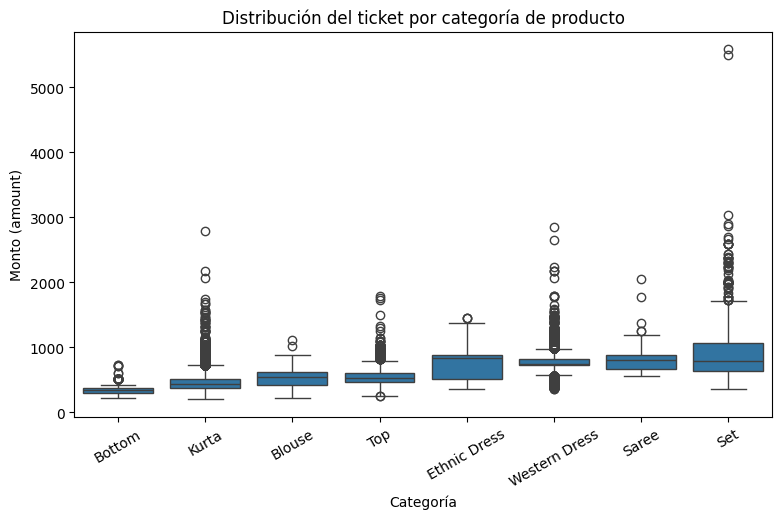

In [81]:
# se excluye Dupatta por tener solo 3 ventas validas
categorias_h3 = [c for c in ventas['category'].unique() if c != 'Dupatta']
grupos_categoria = [ventas.loc[ventas['category'] == c, 'amount'] for c in categorias_h3]

# boxplot de apoyo, ticket por categoría
plt.figure(figsize=(9, 5))
orden_categorias = ventas.groupby('category')['amount'].mean().sort_values().index
orden_categorias = [c for c in orden_categorias if c != 'Dupatta']
sns.boxplot(data=ventas[ventas['category'] != 'Dupatta'], x='category', y='amount', order=orden_categorias)
plt.xlabel('Categoría')
plt.ylabel('Monto (amount)')
plt.title('Distribución del ticket por categoría de producto')
plt.xticks(rotation=30)
plt.show()

In [82]:
# verificación de normalidad con D'Agostino Pearson, una prueba por categoría
for c in categorias_h3:
    muestra = ventas.loc[ventas['category'] == c, 'amount']
    estad, p_norm = stats.normaltest(muestra)
    print(f'{c}: n = {len(muestra)}, estadístico = {estad:.2f}, p = {p_norm:.3e}')

Kurta: n = 41592, estadístico = 17511.36, p = 0.000e+00
Top: n = 9153, estadístico = 1496.45, p = 0.000e+00
Set: n = 41763, estadístico = 10157.64, p = 0.000e+00
Western Dress: n = 13132, estadístico = 6200.88, p = 0.000e+00
Ethnic Dress: n = 981, estadístico = 9.64, p = 8.048e-03
Bottom: n = 367, estadístico = 64.33, p = 1.073e-14
Saree: n = 142, estadístico = 113.75, p = 1.993e-25
Blouse: n = 783, estadístico = 10.34, p = 5.696e-03


Insights:

En las 8 categorías evaluadas se rechaza la normalidad (p mucho menor que alfa en todas). Igual que en H2, los tamaños de muestra son grandes en la mayoría de las categorías (desde 142 en Saree hasta 41,763 en Set), así que por el teorema del límite central el ANOVA de Welch y la prueba t de Welch siguen siendo razonables; se agrega Kruskal-Wallis como robustez.

In [83]:
# homogeneidad de varianzas con Levene
lev_stat_h3, lev_p_h3 = stats.levene(*grupos_categoria)
print(f'Levene: estadístico = {lev_stat_h3:.2f}, p = {lev_p_h3:.3e}')

Levene: estadístico = 2829.75, p = 0.000e+00


Insights:

Levene: estadístico = 2,829.75, p prácticamente 0, menor que alfa. No se cumple la homogeneidad de varianzas entre categorías, así que se usa el ANOVA de Welch en lugar del ANOVA clásico.

In [84]:
# ANOVA de Welch, ticket entre categorías
F_h3, gl1_h3, gl2_h3, p_h3 = anova_welch(grupos_categoria)
print(f'ANOVA de Welch: F = {F_h3:.2f}, gl1 = {gl1_h3}, gl2 = {gl2_h3:.1f}, p = {p_h3:.3e}')

# tamaño del efecto con eta cuadrada
media_general_h3 = ventas.loc[ventas['category'] != 'Dupatta', 'amount'].mean()
ss_entre_h3 = sum(len(g) * (g.mean() - media_general_h3) ** 2 for g in grupos_categoria)
ss_total_h3 = ((ventas.loc[ventas['category'] != 'Dupatta', 'amount'] - media_general_h3) ** 2).sum()
eta2_h3 = ss_entre_h3 / ss_total_h3
print(f'eta cuadrada = {eta2_h3:.4f}')

# robustez: Kruskal-Wallis
kw_h3 = stats.kruskal(*grupos_categoria)
print(f'Kruskal-Wallis: H = {kw_h3.statistic:.2f}, p = {kw_h3.pvalue:.3e}')

ventas.loc[ventas['category'] != 'Dupatta'].groupby('category')['amount'].agg(['count', 'mean', 'std']).sort_values('mean')

ANOVA de Welch: F = 14495.33, gl1 = 7, gl2 = 1723.3, p = 0.000e+00
eta cuadrada = 0.4483
Kruskal-Wallis: H = 59223.84, p = 0.000e+00


,count,mean,std
category,,,
Bottom,367,369.081744,94.918048
Kurta,41592,466.251419,137.208685
Blouse,783,533.983397,152.761590
Top,9153,535.294985,132.513607
Ethnic Dress,981,746.935780,237.212126
Western Dress,13132,777.041654,138.876799
Saree,142,807.704225,198.257651
Set,41763,854.297799,269.977376


Insights:

ANOVA de Welch: F = 14,495.33, gl1 = 7, gl2 = 1,723.3, p prácticamente 0. Se rechaza H0: el ticket promedio sí difiere entre categorías. Kruskal-Wallis confirma el resultado (H = 59,223.84, p prácticamente 0).

La eta cuadrada es 0.4483, un tamaño de efecto grande según los umbrales convencionales (mayor a 0.14), el efecto más fuerte de todo este paso: la categoría explica cerca del 44.8% de la variación del ticket. Las medias van de 369.08 rupias en Bottom a 854.30 rupias en Set, con Kurta en 466.25, Blouse en 533.98, Top en 535.29, Ethnic Dress en 746.94, Western Dress en 777.04 y Saree en 807.70.

**Prueba t de Welch planeada: Set contra Kurta**

**Objetivo:** el ANOVA solo dice que al menos una categoría es distinta. Set y Kurta son las dos categorías más vendidas con mucha diferencia (41,763 y 41,592 ventas validas respectivamente, juntas casi el 78% de las ventas validas), así que se elige esta comparación planeada en vez de los extremos absolutos (Set contra Bottom), porque son los dos productos que de verdad mueven el negocio y la comparación tiene el respaldo de dos muestras muy grandes.

- H0: el ticket promedio es igual en Set y en Kurta.
- H1: el ticket promedio es distinto entre Set y Kurta.

In [85]:
# prueba t de Welch, ticket de Set contra Kurta
ticket_set = ventas.loc[ventas['category'] == 'Set', 'amount']
ticket_kurta = ventas.loc[ventas['category'] == 'Kurta', 'amount']
t_h3, gl_t_h3, p_t_h3, dif_h3, ic_low_h3, ic_high_h3, d_h3 = prueba_t_welch(ticket_set, ticket_kurta)

print(f't = {t_h3:.2f}, gl = {gl_t_h3:.1f}, p = {p_t_h3:.3e}')
print(f'diferencia de medias = {dif_h3:.2f}, IC 95% = ({ic_low_h3:.2f}, {ic_high_h3:.2f})')
print(f'd de Cohen = {d_h3:.3f}')

mw_h3 = stats.mannwhitneyu(ticket_set, ticket_kurta)
print(f'Mann-Whitney U = {mw_h3.statistic:.0f}, p = {mw_h3.pvalue:.3e}')

t = 261.75, gl = 62042.8, p = 0.000e+00
diferencia de medias = 388.05, IC 95% = (385.14, 390.95)
d de Cohen = 1.812
Mann-Whitney U = 1619036696, p = 0.000e+00


Insights:

t = 261.75, gl = 62,042.8, p prácticamente 0. Se rechaza H0, y Mann-Whitney U confirma el resultado. La diferencia de medias es de 388.05 rupias (854.30 en Set contra 466.25 en Kurta), con un intervalo de confianza del 95% entre 385.14 y 390.95 rupias. La d de Cohen es 1.812, un tamaño de efecto grande, muy por encima del umbral de 0.8.

Lectura de negocio: Set es, por mucho, la categoría de mayor ticket entre los dos productos que dominan el volumen de ventas; su ticket promedio prácticamente duplica al de Kurta. Esto tiene sentido de negocio (un Set suele incluir más de una prenda) y es el hallazgo de mayor tamaño de efecto de todo el Paso 5.

### 5.5 H4: nivel de servicio de envío y cancelación

**Objetivo:** evaluar si el nivel de servicio de envío (`ship_service_level`: Expedited o Standard) está asociado con la cancelación del pedido. Antes de interpretar la prueba se revisa la relación entre `ship_service_level` y `fulfilment`, porque estan casi confundidas.

- H0: el nivel de servicio y la cancelación son independientes.
- H1: el nivel de servicio y la cancelación estan asociados.

In [86]:
# fulfilment y nivel de servicio, estan casi confundidos?
pd.crosstab(df['fulfilment'], df['ship_service_level'])

ship_service_level,Expedited,Standard
fulfilment,,
Amazon,88461,1083
Merchant,0,39254


Insights:

Si, estan casi confundidos. Merchant es 100% Standard (39,254 de 39,254 líneas). Amazon es casi todo Expedited (88,461 líneas) y solo tiene 1,083 líneas Standard. Es decir, dentro de Merchant no hay ninguna variación en `ship_service_level` para comparar, y casi toda la variación de Standard contra Expedited que existe en los datos viene de una porción chica de Amazon. Cualquier prueba de `ship_service_level` contra `cancelado` sin tomar esto en cuenta va a mezclar, en la práctica, el efecto del fulfilment con el del nivel de servicio.

In [87]:
# chi cuadrado de independencia, ship_service_level contra cancelado (con las 128,798 líneas)
tabla_h4 = pd.crosstab(df['ship_service_level'], df['cancelado'])
chi2_h4, p_h4, gl_h4, esperado_h4, v_h4 = prueba_chi2_cramer(tabla_h4)

print(tabla_h4)
print(f'chi2 = {chi2_h4:.2f}, gl = {gl_h4}, p = {p_h4:.3e}')
print('frecuencia esperada mínima:', round(esperado_h4.min(), 2))
print('V de Cramér:', round(v_h4, 4))

cancelado           False  True 
ship_service_level              
Expedited           77053  11408
Standard            33434   6903
chi2 = 403.67, gl = 1, p = 8.750e-90
frecuencia esperada mínima: 5734.65
V de Cramér: 0.056


Insights:

chi2 = 403.67, gl = 1, p = 8.75e-90, menor que alfa. Se rechaza H0 en la prueba sin estratificar, con una V de Cramér de 0.056 (efecto casi nulo). La tasa de cancelación es de 12.94% en Expedited (11,408 de 88,461) y de 17.11% en Standard (6,903 de 40,337).

Sin embargo, como se vio arriba, esta prueba mezcla fulfilment con nivel de servicio: casi todo Standard es Merchant, y en H1 ya se vio que Merchant tiene más cancelación que Amazon. No se puede atribuir esta diferencia solo al nivel de servicio sin controlar por fulfilment primero.

In [88]:
# prueba estratificada dentro de Amazon, donde sí hay variación en ambos niveles de servicio
amazon = df[df['fulfilment'] == 'Amazon']
tabla_h4_amazon = pd.crosstab(amazon['ship_service_level'], amazon['cancelado'])
chi2_h4a, p_h4a, gl_h4a, esperado_h4a, v_h4a = prueba_chi2_cramer(tabla_h4_amazon)

print(tabla_h4_amazon)
print(f'chi2 = {chi2_h4a:.2f}, gl = {gl_h4a}, p = {p_h4a:.3e}')
print('frecuencia esperada mínima:', round(esperado_h4a.min(), 2))
print('V de Cramér:', round(v_h4a, 4))

tasa_expedited = tabla_h4_amazon.loc['Expedited', True] / tabla_h4_amazon.loc['Expedited'].sum()
tasa_standard = tabla_h4_amazon.loc['Standard', True] / tabla_h4_amazon.loc['Standard'].sum()
dif_h4a, ic_low_h4a, ic_high_h4a = ic_diferencia_proporciones(
    tabla_h4_amazon.loc['Expedited', True], tabla_h4_amazon.loc['Expedited'].sum(),
    tabla_h4_amazon.loc['Standard', True], tabla_h4_amazon.loc['Standard'].sum(),
)
print(f'tasa de cancelación Expedited (Amazon): {tasa_expedited * 100:.2f}%')
print(f'tasa de cancelación Standard (Amazon): {tasa_standard * 100:.2f}%')
print(f'diferencia (Expedited menos Standard) = {dif_h4a * 100:.2f} puntos porcentuales, IC 95% = ({ic_low_h4a * 100:.2f}, {ic_high_h4a * 100:.2f})')

cancelado           False  True 
ship_service_level              
Expedited           77053  11408
Standard             1035     48
chi2 = 67.94, gl = 1, p = 1.684e-16
frecuencia esperada mínima: 138.56
V de Cramér: 0.0275
tasa de cancelación Expedited (Amazon): 12.90%
tasa de cancelación Standard (Amazon): 4.43%
diferencia (Expedited menos Standard) = 8.46 puntos porcentuales, IC 95% = (7.22, 9.71)


Insights:

Dentro de Amazon, la frecuencia esperada mínima es de 138.56, por encima de 5, así que se cumple el supuesto de chi cuadrado. chi2 = 67.94, gl = 1, p = 1.68e-16, menor que alfa. Se rechaza H0 también dentro de Amazon, con una V de Cramér de 0.028 (efecto prácticamente nulo, más chico todavía que en la prueba sin estratificar).

La tasa de cancelación es de 12.90% en Expedited (11,408 de 88,461 líneas de Amazon) contra 4.43% en Standard (48 de 1,083 líneas), una diferencia de 8.46 puntos porcentuales con IC 95% entre 7.22 y 9.71 (aquí Standard cancela menos, aunque hay que tomar el grupo Standard de Amazon con cautela por ser chico, apenas 1,083 líneas frente a 88,461 en Expedited).

Es importante notar que la dirección de la diferencia se invierte al estratificar: sin controlar por fulfilment, Standard cancela más que Expedited (17.11% contra 12.94%), pero dentro de Amazon Standard cancela menos (4.43% contra 12.90%). Es un caso de paradoja de Simpson, donde el patrón agregado se explica por la composición de los grupos (casi todo Standard es Merchant) y no por el nivel de servicio.

Lectura con cautela: la asociación entre nivel de servicio y cancelación es estadísticamente significativa incluso dentro de Amazon, pero su tamaño de efecto es casi nulo (V = 0.028) y el grupo Standard de Amazon es pequeño. Dentro de Merchant no se puede evaluar nada porque no hay variación en `ship_service_level` (es 100% Standard). En conjunto, la mayor parte de la diferencia de cancelación que se observa al mirar solo `ship_service_level` (V = 0.056) es atribuible al fulfilment (H1, V también pequeño pero con una diferencia de tasas mayor, 4.67 puntos porcentuales) y no al nivel de servicio en sí mismo, que aporta un efecto adicional muy pequeño.

### 5.6 H5: ticket en el tiempo

**Objetivo:** evaluar si el ticket promedio difiere (a) entre los tres meses del periodo analizado y (b) entre fin de semana y días hábiles. También se revisa si el mes está asociado con la cancelación.

- H0 (mes): la distribución del ticket es la misma en abril, mayo y junio.
- H1 (mes): al menos un mes difiere de los demas en su ticket promedio.
- H0 (fin de semana): el ticket promedio es igual en fin de semana y en días hábiles.
- H1 (fin de semana): el ticket promedio es distinto entre fin de semana y días hábiles.

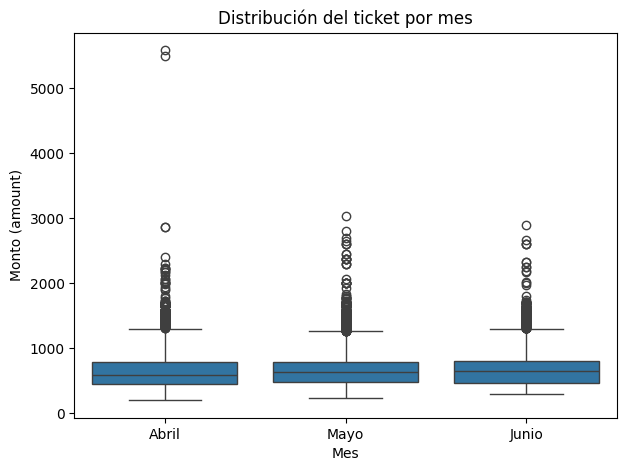

In [89]:
# boxplot de apoyo, ticket por mes
plt.figure(figsize=(7, 5))
orden_meses = ['Abril', 'Mayo', 'Junio']
sns.boxplot(data=ventas, x='mes_nombre', y='amount', order=orden_meses)
plt.xlabel('Mes')
plt.ylabel('Monto (amount)')
plt.title('Distribución del ticket por mes')
plt.show()

In [90]:
# verificación de normalidad con D'Agostino Pearson, una prueba por mes
grupos_mes = [ventas.loc[ventas['mes_nombre'] == m, 'amount'] for m in orden_meses]
for m, g in zip(orden_meses, grupos_mes):
    estad, p_norm = stats.normaltest(g)
    print(f'{m}: n = {len(g)}, estadístico = {estad:.2f}, p = {p_norm:.3e}')

Abril: n = 41006, estadístico = 13550.62, p = 0.000e+00
Mayo: n = 35344, estadístico = 6573.28, p = 0.000e+00
Junio: n = 31566, estadístico = 3890.74, p = 0.000e+00


Insights:

En los tres meses se rechaza la normalidad (p prácticamente 0). Igual que en las pruebas anteriores, los tamaños de muestra son grandes (entre 31,566 y 41,006 observaciones por mes), así que por el teorema del límite central el ANOVA de Welch sigue siendo razonable; se agrega Kruskal-Wallis como robustez.

In [91]:
# homogeneidad de varianzas con Levene
lev_stat_h5a, lev_p_h5a = stats.levene(*grupos_mes)
print(f'Levene: estadístico = {lev_stat_h5a:.2f}, p = {lev_p_h5a:.3e}')

Levene: estadístico = 51.02, p = 7.108e-23


Insights:

Levene: estadístico = 51.02, p = 7.11e-23, menor que alfa. No se cumple la homogeneidad de varianzas entre meses, así que se usa el ANOVA de Welch en lugar del ANOVA clásico.

In [92]:
# ANOVA de Welch, ticket entre meses
F_h5a, gl1_h5a, gl2_h5a, p_h5a = anova_welch(grupos_mes)
print(f'ANOVA de Welch: F = {F_h5a:.2f}, gl1 = {gl1_h5a}, gl2 = {gl2_h5a:.1f}, p = {p_h5a:.3e}')

# tamaño del efecto con eta cuadrada
media_general_h5a = ventas['amount'].mean()
ss_entre_h5a = sum(len(g) * (g.mean() - media_general_h5a) ** 2 for g in grupos_mes)
ss_total_h5a = ((ventas['amount'] - media_general_h5a) ** 2).sum()
eta2_h5a = ss_entre_h5a / ss_total_h5a
print(f'eta cuadrada = {eta2_h5a:.4f}')

# robustez: Kruskal-Wallis
kw_h5a = stats.kruskal(*grupos_mes)
print(f'Kruskal-Wallis: H = {kw_h5a.statistic:.2f}, p = {kw_h5a.pvalue:.3e}')

ventas.groupby('mes_nombre')['amount'].agg(['count', 'mean', 'std']).loc[orden_meses]

ANOVA de Welch: F = 257.06, gl1 = 2, gl2 = 69670.8, p = 5.918e-112
eta cuadrada = 0.0047
Kruskal-Wallis: H = 604.55, p = 5.286e-132


,count,mean,std
mes_nombre,,,
Abril,41006,639.772716,262.382891
Mayo,35344,677.683963,270.808432
Junio,31566,677.607774,274.885965


Insights:

ANOVA de Welch: F = 257.06, gl1 = 2, gl2 = 69,670.8, p = 5.92e-112, mucho menor que alfa. Se rechaza H0: el ticket promedio sí difiere entre meses. Kruskal-Wallis confirma el resultado (H = 604.55, p = 5.29e-132).

La eta cuadrada es 0.0047, un tamaño de efecto prácticamente nulo (muy por debajo del umbral de 0.01 para efecto pequeño). Las medias son de 639.77 rupias en abril, 677.68 en mayo y 677.61 en junio: hay una diferencia real y estadísticamente significativa, pero el mes explica menos del 0.5% de la variación del ticket. En términos prácticos, el ticket es muy parecido en los tres meses (una diferencia de unas 38 rupias entre abril y los otros dos meses, sobre un ticket promedio de 663 rupias).

In [93]:
# prueba t de Welch, ticket en fin de semana contra días hábiles
grupo_finde = ventas.loc[ventas['fin_de_semana'], 'amount']
grupo_habil = ventas.loc[~ventas['fin_de_semana'], 'amount']

lev_stat_h5b, lev_p_h5b = stats.levene(grupo_finde, grupo_habil)
print(f'Levene: estadístico = {lev_stat_h5b:.2f}, p = {lev_p_h5b:.3e}')

t_h5b, gl_h5b, p_h5b, dif_h5b, ic_low_h5b, ic_high_h5b, d_h5b = prueba_t_welch(grupo_finde, grupo_habil)
print(f't = {t_h5b:.2f}, gl = {gl_h5b:.1f}, p = {p_h5b:.3e}')
print(f'diferencia de medias = {dif_h5b:.2f}, IC 95% = ({ic_low_h5b:.2f}, {ic_high_h5b:.2f})')
print(f'd de Cohen = {d_h5b:.3f}')

ventas.groupby('fin_de_semana')['amount'].agg(['count', 'mean', 'std'])

Levene: estadístico = 0.06, p = 8.022e-01
t = 1.15, gl = 60343.9, p = 2.485e-01
diferencia de medias = 2.07, IC 95% = (-1.45, 5.59)
d de Cohen = 0.008


,count,mean,std
fin_de_semana,,,
False,75912,662.642336,269.733657
True,32004,664.712036,268.864559


Insights:

Levene: estadístico = 0.06, p = 0.802, mayor que alfa, así que aquí sí se cumple la homogeneidad de varianzas (se deja la versión de Welch de cualquier forma, por consistencia con el resto del paso).

t = 1.15, gl = 60,343.9, p = 0.249, mayor que alfa. No se rechaza H0: no hay evidencia suficiente de que el ticket promedio difiera entre fin de semana (664.71 rupias, n = 32,004) y días hábiles (662.64 rupias, n = 75,912). La diferencia de medias es de solo 2.07 rupias, con un intervalo de confianza del 95% entre -1.45 y 5.59 que cruza el cero, y la d de Cohen es 0.008, prácticamente nula.

Lectura de negocio: a diferencia del mes, que sí mostró una diferencia estadísticamente significativa (aunque de tamaño nulo), el día de la semana no muestra ni siquiera significancia estadística. El comportamiento de compra en cuanto a ticket promedio es indistinguible entre fin de semana y días hábiles.

In [94]:
# chi cuadrado de mes contra cancelado
tabla_h5c = pd.crosstab(df['mes_nombre'], df['cancelado']).loc[orden_meses]
chi2_h5c, p_h5c, gl_h5c, esperado_h5c, v_h5c = prueba_chi2_cramer(tabla_h5c)

print(tabla_h5c)
print(f'chi2 = {chi2_h5c:.2f}, gl = {gl_h5c}, p = {p_h5c:.3e}')
print('frecuencia esperada mínima:', round(esperado_h5c.min(), 2))
print('V de Cramér:', round(v_h5c, 4))

for m in orden_meses:
    tasa = tabla_h5c.loc[m, True] / tabla_h5c.loc[m].sum()
    print(f'tasa de cancelación en {m}: {tasa * 100:.2f}%')

cancelado   False  True 
mes_nombre              
Abril       41930   7135
Mayo        36164   5873
Junio       32393   5303
chi2 = 7.02, gl = 2, p = 2.988e-02
frecuencia esperada mínima: 5359.18
V de Cramér: 0.0074
tasa de cancelación en Abril: 14.54%
tasa de cancelación en Mayo: 13.97%
tasa de cancelación en Junio: 14.07%


Insights:

chi2 = 7.02, gl = 2, p = 0.0299, apenas por debajo de alfa. La frecuencia esperada mínima es de 5,359.18, muy por encima de 5. Se rechaza H0, pero con un p valor cercano a 0.05, así que el resultado es fragil. La V de Cramér es 0.0074, un efecto nulo. La tasa de cancelación es de 14.54% en abril, 13.97% en mayo y 14.07% en junio: hay algo de variación entre meses, pero es mínima y estadísticamente el resultado no es robusto. En la práctica, la tasa de cancelación se mantiene estable a lo largo del trimestre.

### 5.7 H6: pedidos B2B contra B2C

**Objetivo:** evaluar si el ticket promedio difiere entre pedidos B2B y B2C, y si la cancelación está asociada con ser B2B. La cantidad de pedidos B2B es chica (797 ventas validas, contra 107,119 B2C), así que se pone especial atención a la robustez de la prueba de ticket.

- H0 (ticket): el ticket promedio es igual entre pedidos B2B y B2C.
- H1 (ticket): el ticket promedio es distinto entre pedidos B2B y B2C.
- H0 (cancelación): ser B2B y la cancelación son independientes.
- H1 (cancelación): ser B2B y la cancelación estan asociados.

B2B: n = 797, estadístico = 819.49, p = 1.123e-178
B2C: n = 107119, estadístico = 20811.41, p = 0.000e+00


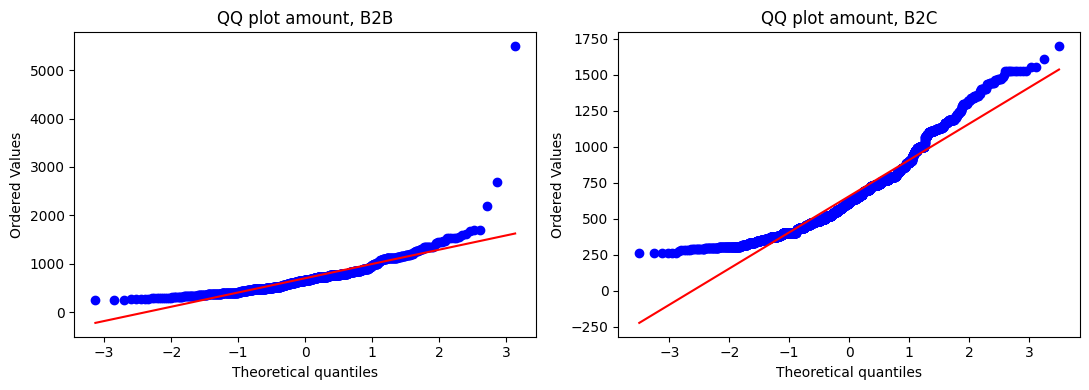

In [95]:
# verificación de normalidad con D'Agostino Pearson
grupo_b2b = ventas.loc[ventas['b2b'], 'amount']
grupo_b2c = ventas.loc[~ventas['b2b'], 'amount']

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nombre, muestra in zip(axes, ['B2B', 'B2C'], [grupo_b2b, grupo_b2c]):
    estad, p_norm = stats.normaltest(muestra)
    print(f'{nombre}: n = {len(muestra)}, estadístico = {estad:.2f}, p = {p_norm:.3e}')
    muestra_qq = muestra.sample(min(3000, len(muestra)), random_state=42)
    stats.probplot(muestra_qq, dist='norm', plot=ax)
    ax.set_title(f'QQ plot amount, {nombre}')
plt.tight_layout()
plt.show()

Insights:

En los dos grupos se rechaza la normalidad (p menor que alfa). El grupo B2C tiene un tamaño de muestra enorme (107,119), así que el teorema del límite central se cumple sin problema. El grupo B2B es más chico (797), pero sigue siendo lo bastante grande (bastante mayor a 30) para que la aproximación normal de la media sea razonable; aun así, se agrega Mann-Whitney U como robustez adicional dado el tamaño más modesto de este grupo.

In [96]:
# homogeneidad de varianzas con Levene
lev_stat_h6, lev_p_h6 = stats.levene(grupo_b2b, grupo_b2c)
print(f'Levene: estadístico = {lev_stat_h6:.2f}, p = {lev_p_h6:.3e}')

Levene: estadístico = 6.84, p = 8.937e-03


Insights:

Levene: estadístico = 6.84, p = 0.0089, menor que alfa. No se cumple la homogeneidad de varianzas, así que se usa la prueba t de Welch.

In [97]:
# prueba t de Welch, ticket B2B contra B2C
t_h6, gl_h6, p_h6, dif_h6, ic_low_h6, ic_high_h6, d_h6 = prueba_t_welch(grupo_b2b, grupo_b2c)
print(f't = {t_h6:.2f}, gl = {gl_h6:.1f}, p = {p_h6:.3e}')
print(f'diferencia de medias = {dif_h6:.2f}, IC 95% = ({ic_low_h6:.2f}, {ic_high_h6:.2f})')
print(f'd de Cohen = {d_h6:.3f}')

mw_h6 = stats.mannwhitneyu(grupo_b2b, grupo_b2c)
print(f'Mann-Whitney U = {mw_h6.statistic:.0f}, p = {mw_h6.pvalue:.3e}')

ventas.groupby('b2b')['amount'].agg(['count', 'mean', 'median', 'std'])

t = 3.25, gl = 803.6, p = 1.194e-03
diferencia de medias = 38.91, IC 95% = (15.42, 62.40)
d de Cohen = 0.128
Mann-Whitney U = 45559832, p = 1.042e-03


,count,mean,median,std
b2b,,,,
False,107119,662.968745,625.0,268.891637
True,797,701.882058,665.0,337.023647


Insights:

t = 3.25, gl = 803.6, p = 0.0012, menor que alfa. Se rechaza H0: el ticket promedio sí difiere entre pedidos B2B y B2C. Mann-Whitney U confirma el resultado (p = 0.0010), así que la conclusión no depende de la normalidad.

La diferencia de medias es de 38.91 rupias (701.88 en B2B contra 662.97 en B2C), con un intervalo de confianza del 95% entre 15.42 y 62.40 rupias. La d de Cohen es 0.128, un tamaño de efecto pequeño, por debajo del umbral convencional de 0.2.

Lectura de negocio: los pedidos B2B tienen, en promedio, un ticket algo mayor que los B2C, y la diferencia es estadísticamente significativa incluso con un grupo B2B relativamente chico. Pero en términos prácticos la diferencia es modesta (unas 39 rupias sobre un ticket promedio de 663), así que B2B no representa un segmento de ticket dramaticamente distinto, solo ligeramente superior.

In [98]:
# chi cuadrado de b2b contra cancelado
tabla_h6b = pd.crosstab(df['b2b'], df['cancelado'])
chi2_h6b, p_h6b, gl_h6b, esperado_h6b, v_h6b = prueba_chi2_cramer(tabla_h6b)

print(tabla_h6b)
print(f'chi2 = {chi2_h6b:.2f}, gl = {gl_h6b}, p = {p_h6b:.3e}')
print('frecuencia esperada mínima:', round(esperado_h6b.min(), 2))
print('V de Cramér:', round(v_h6b, 4))

tasa_b2b = tabla_h6b.loc[True, True] / tabla_h6b.loc[True].sum()
tasa_b2c = tabla_h6b.loc[False, True] / tabla_h6b.loc[False].sum()
print(f'tasa de cancelación B2B: {tasa_b2b * 100:.2f}%')
print(f'tasa de cancelación B2C: {tasa_b2c * 100:.2f}%')

cancelado   False  True 
b2b                     
False      109689  18238
True          798     73
chi2 = 24.01, gl = 1, p = 9.594e-07
frecuencia esperada mínima: 123.83
V de Cramér: 0.0137
tasa de cancelación B2B: 8.38%
tasa de cancelación B2C: 14.26%


Insights:

La frecuencia esperada mínima es de 123.83, por encima de 5, así que se cumple el supuesto de chi cuadrado a pesar del tamaño chico del grupo B2B. chi2 = 24.01, gl = 1, p = 9.59e-07, menor que alfa. Se rechaza H0: la cancelación sí está asociada con ser B2B. La V de Cramér es 0.0137, un tamaño de efecto prácticamente nulo.

La tasa de cancelación es de 8.38% en B2B (73 de 871) contra 14.26% en B2C (18,238 de 127,927). Aunque el resultado es estadísticamente significativo, el tamaño de efecto es nulo y el grupo B2B es chico (73 cancelaciones en total), así que esta diferencia se interpreta con cautela: los pedidos B2B parecen cancelarse un poco menos, pero no es un patron con fuerza práctica relevante.

### Observaciones del Paso 5

**Comentario:**

Resumen de todas las pruebas de hipótesis de este paso (alfa = 0.05):

| Hipótesis | Prueba | Estadístico | p | Tamaño de efecto | Decisión |
|---|---|---|---|---|---|
| H1: fulfilment y cancelación | chi cuadrado | chi2 = 487.53, gl = 1 | 4.91e-108 | V = 0.0615 (pequeño) | Se rechaza H0 |
| H2a: ticket con promoción vs sin promoción | prueba t de Welch | t = 35.53 | 2.45e-273 | d = 0.243 (pequeño) | Se rechaza H0 |
| H2a: ticket con/sin promoción, estrato Amazon | prueba t de Welch | t = 37.27 | 1.07e-300 | d = 0.277 (pequeño) | Se rechaza H0 |
| H2a: ticket con/sin promoción, estrato Merchant | prueba t de Welch | t = 0.84 | 0.410 | d = 0.182 (no concluyente, solo 20 líneas sin promoción) | No se rechaza H0 |
| H2b: promoción y cancelación | chi cuadrado (diagnóstico) | chi2 = 32877.41, gl = 1 | prácticamente 0 | V = 0.505 (grande) | No interpretable (artefacto de registro) |
| H3: ticket entre categorías | ANOVA de Welch | F = 14495.33 | prácticamente 0 | eta2 = 0.4483 (grande) | Se rechaza H0 |
| H3: ticket, Set contra Kurta | prueba t de Welch | t = 261.75 | prácticamente 0 | d = 1.812 (grande) | Se rechaza H0 |
| H4: nivel de servicio y cancelación (sin estratificar) | chi cuadrado | chi2 = 403.67, gl = 1 | 8.75e-90 | V = 0.056 (casi nulo) | Se rechaza H0 |
| H4: nivel de servicio y cancelación, estrato Amazon | chi cuadrado | chi2 = 67.94, gl = 1 | 1.68e-16 | V = 0.028 (nulo) | Se rechaza H0 |
| H5: ticket entre meses | ANOVA de Welch | F = 257.06 | 5.92e-112 | eta2 = 0.0047 (nulo) | Se rechaza H0 |
| H5: ticket, fin de semana contra días hábiles | prueba t de Welch | t = 1.15 | 0.249 | d = 0.008 (nulo) | No se rechaza H0 |
| H5: mes y cancelación | chi cuadrado | chi2 = 7.02, gl = 2 | 0.0299 | V = 0.0074 (nulo) | Se rechaza H0 (frágil) |
| H6: ticket B2B contra B2C | prueba t de Welch | t = 3.25 | 0.0012 | d = 0.128 (pequeño) | Se rechaza H0 |
| H6: B2B y cancelación | chi cuadrado | chi2 = 24.01, gl = 1 | 9.59e-07 | V = 0.0137 (nulo) | Se rechaza H0 |

Con un dataset de más de 100,000 líneas de pedido, casi todas las pruebas de este paso resultan estadísticamente significativas, incluidas diferencias que en la práctica son mínimas (el mes, el fin de semana, ser B2B). Por eso el tamaño de efecto es la guía principal para decidir qué hallazgos importan de verdad para el negocio:

- El efecto más grande, por mucho, es la categoría de producto sobre el ticket (H3, eta2 = 0.4483; Set contra Kurta, d = 1.812): el tipo de prenda es el factor que más explica cuánto paga un cliente.
- El segundo estadístico más grande de este paso (H2b, V = 0.505) no se interpreta como hallazgo de negocio: `promotion_ids` se captura casi solo cuando el pedido se envía (71.23% en Enviado, 99.81% en Devuelto) y casi nunca cuando se cancela (1.61% en Cancelado, y los 6,855 cancelados con `courier_status` 'Sin dato' tienen 0 promociones), así que es una variable posterior al resultado y no un predictor válido de la cancelación. Se documenta como artefacto de registro, no como evidencia de que las promociones reduzcan cancelaciones.
- El fulfilment (Amazon vs Merchant) es el factor más claro y confiable sobre la cancelación: Merchant cancela 4.67 puntos porcentuales más que Amazon (H1), y ese efecto persiste (aunque muy atenuado, V = 0.028) incluso después de controlar por nivel de servicio de envío dentro de Amazon (H4). El nivel de servicio en sí mismo aporta muy poco una vez que se separa del fulfilment.
- Las promociones sí se asocian con un ticket algo mayor (H2a, d = 0.243, y se mantiene dentro de Amazon con d = 0.277), y los pedidos B2B tienen un ticket un poco más alto que B2C (H6, d = 0.128), pero ambos son efectos pequeños en términos prácticos (65 y 39 rupias respectivamente, sobre un ticket promedio de 663 rupias).
- El tiempo (mes y día de la semana) prácticamente no afecta el ticket promedio ni la cancelación: todas las diferencias relacionadas con el tiempo tienen tamaños de efecto nulos o casi nulos, aunque el volumen de pedidos sí varía por mes (ver Paso 4). Las ventas de Amazon India en este periodo se comportan de forma bastante estable a lo largo del trimestre.

## Paso 6: Insight ejecutivo y conclusiones

**Objetivo:** Traducir los hallazgos de todo el análisis en conclusiones claras y accionables, retomando la pregunta central del proyecto.

Respondemos las siguientes preguntas:

- ¿Qué problemas tenía originalmente el dataset y qué tan graves eran?
- ¿Qué factores operativos y comerciales están asociados con la cancelación de pedidos y con el valor del ticket en las ventas de Amazon India (la pregunta central del análisis)?
- ¿Qué otros factores importan, y cuáles no?
- ¿Qué se recomienda a partir de estos hallazgos, y qué limitaciones tiene el análisis?


### Análisis ejecutivo

**Calidad de datos:**

El dataset original (`Amazon Sale Report.csv`) llegó con 128,975 filas y 24 columnas, con varios problemas de calidad manejables. No había duplicados relevantes fuera de 6 filas completamente iguales (eliminadas en el Paso 3), aunque `Order ID` se repite en 8,597 filas porque un mismo pedido puede tener varias líneas (SKU); por eso la unidad de análisis se definió como línea de pedido, no pedido completo. Los nulos más relevantes fueron `fulfilled-by` (69.55%, redundante con `Fulfilment` y por eso se eliminó), `promotion-ids` (38.11%) y `Unnamed: 22` (38.03%, columna basura sin contenido útil, también eliminada), además de `Courier Status` (5.33%) y `currency`/`Amount` (6.04% cada una). Al investigar el mecanismo de los nulos de `Amount` con chi cuadrado, se confirmó que dependen directamente de si el pedido fue cancelado (mecanismo MAR): 41.27% de los pedidos Cancelled tienen `Amount` nulo, contra menos de 0.3% en el resto de los estatus (chi2 = 46,844.88, p menor a 0.0001); lo mismo aplica a `Courier Status` (chi2 = 43,647.10, p menor a 0.0001). Por eso `Amount` no se imputó, se dejó como reflejo natural de una venta que no se concretó, y se creó el indicador `venta_valida` para separar el análisis del ticket. También se corrigieron columnas constantes (`currency`, `ship-country`), inconsistencias de mayúsculas en `Category` y `ship-state`, y se excluyó el 31 de marzo por representar un mes incompleto (171 filas). El dataset limpio quedó en 128,798 líneas de pedido (120,220 pedidos únicos), de las cuales 107,916 son ventas válidas (no canceladas, con monto positivo) usadas para todo el análisis de ticket.

**Respuesta a la pregunta central:**

Sí: hay factores operativos y comerciales claramente asociados con la cancelación y con el ticket, aunque de magnitudes muy distintas y con varias advertencias de interpretación confirmadas en el Paso 5 (alfa = 0.05).

Sobre cancelación, el factor más confiable es el fulfilment: los pedidos Amazon cancelan 12.79% de las veces contra 17.46% en Merchant, una diferencia de 4.67 puntos porcentuales (IC 95% de 4.23 a 5.10; chi cuadrado = 487.53, p = 4.91e-108, V de Cramér = 0.0615, efecto pequeño pero consistente en las cuatro celdas de la tabla). El nivel de servicio de envío (`ship_service_level`) está casi confundido con fulfilment: Merchant es 100% Standard y Amazon es 98.79% Expedited. Sin estratificar, Standard parece cancelar más (17.11% contra 12.94% en Expedited, V = 0.056), pero al controlar por fulfilment y mirar solo dentro de Amazon, el patrón se invierte: Standard cancela menos (4.43% contra 12.90% en Expedited), un caso claro de paradoja de Simpson. El tamaño de efecto dentro de Amazon es casi nulo (V = 0.028) y el grupo Standard de Amazon es chico (1,083 líneas), así que la mayor parte de la diferencia de cancelación observada se atribuye al fulfilment, no al nivel de servicio en sí.

Sobre el ticket, el factor con el efecto más grande de todo el análisis, por mucho, es la categoría de producto (ANOVA de Welch, eta cuadrada = 0.4483, efecto grande): las medias van de 369.08 INR en Bottom a 854.30 INR en Set. La comparación planeada entre las dos categorías que dominan el volumen, Set (854.30 INR) contra Kurta (466.25 INR), muestra una diferencia de 388.05 INR con d de Cohen = 1.812 (efecto grande), es decir, el ticket de Set casi duplica al de Kurta.

Es indispensable aclarar una limitación crítica del dataset: `promotion_ids` no es una variable capturada de forma independiente del resultado del pedido. El 98.39% de las líneas Canceladas no tiene promoción registrada, contra solo 28.77% de las Enviadas y 0.19% de las Devueltas; el campo se llena sobre todo cuando el pedido efectivamente avanza, casi nunca cuando se cancela antes de esa etapa. Por eso, aunque la prueba de chi cuadrado entre `tiene_promocion` y `cancelado` arroja el segundo tamaño de efecto más grande de todo el Paso 5 (V de Cramér = 0.505), ese resultado no se interpreta como evidencia de que las promociones reduzcan la cancelación: es un artefacto de registro, no un hallazgo de negocio.

**Otros factores:**

El ticket promedio también está asociado, con efectos pequeños o modestos, a tener promoción (680.95 INR contra 615.89 INR sin promoción, diferencia de 65.07 INR, d de Cohen = 0.243; el efecto se sostiene dentro de Amazon con d = 0.277, aunque dentro de Merchant no hay suficiente variación para probarlo, solo 20 líneas sin promoción) y a ser un pedido B2B (701.88 INR contra 662.97 INR en B2C, diferencia de 38.91 INR, d de Cohen = 0.128; B2B representa apenas 797 de 107,916 líneas válidas). La cancelación también está asociada a ser B2B (8.38% contra 14.26% en B2C), pero el tamaño de efecto es prácticamente nulo (V de Cramér = 0.0137).

El tiempo prácticamente no importa: el ticket promedio difiere entre meses de forma estadísticamente significativa (639.77 INR en abril, 677.68 en mayo, 677.61 en junio), pero el efecto es nulo (eta cuadrada = 0.0047), y la diferencia entre fin de semana (664.71 INR) y días hábiles (662.64 INR) ni siquiera es significativa (d de Cohen = 0.008). La asociación entre mes y cancelación es estadísticamente significativa pero frágil (p = 0.0299, muy cerca de alfa) y de tamaño nulo (V = 0.0074). Con un dataset de más de 100,000 líneas de pedido, casi cualquier diferencia resulta significativa, así que el tamaño de efecto, no el p valor, es la guía principal para decidir qué hallazgos importan de verdad.

**Recomendaciones:**

- Investigar y atender el proceso de fulfilment de Merchant, ya que su tasa de cancelación (17.46%) es consistentemente más alta que la de Amazon (12.79%); si Merchant igualara la tasa de Amazon se hubieran evitado del orden de 1,833 cancelaciones en el trimestre.
- No usar el nivel de servicio de envío (Standard o Expedited) como palanca aislada para reducir cancelaciones: su efecto es casi nulo una vez que se separa del fulfilment, y el patrón incluso se invierte según se estratifique o no.
- Priorizar el crecimiento de la categoría Set en la mezcla de producto (ya domina el 49.85% de las ventas y tiene el ticket más alto), y explorar estrategias de upselling de Kurta (segunda categoría en volumen, pero con ticket 45% más bajo) hacia productos tipo Set.
- Corregir el proceso de captura de `promotion_ids` para que se registre desde la creación del pedido y no solo cuando se despacha; así el negocio podría medir en el futuro el efecto real de las promociones sobre la cancelación, algo que este dataset no permite responder hoy.
- No tratar promoción, mes, día de la semana o segmento B2B/B2C como palancas prioritarias para mover el ticket promedio: sus efectos son pequeños o nulos frente al de la categoría de producto.

**Limitaciones y siguientes pasos:**

Es un estudio observacional: todas las pruebas muestran asociación, no causalidad, y ningún hallazgo de este análisis debe leerse como que un factor causa la cancelación o cambia el ticket. El periodo cubierto es corto, solo tres meses completos (abril a junio de 2022), lo que impide evaluar estacionalidad de más largo plazo o comparar contra otros años. El análisis se limitó a `Amazon Sale Report.csv`; los demás archivos de `data/raw/` (`Cloud Warehouse Compersion Chart.csv`, `Expense IIGF.csv`, `International sale Report.csv`, `May-2022.csv`, `P  L March 2021.csv` y `Sale Report.csv`) no se usaron porque tienen estructura y periodos distintos, así que este análisis no cubre inventario, gastos, ventas internacionales ni resultados financieros. La limitación más importante para las recomendaciones de negocio es que `promotion_ids` se captura después de conocerse el resultado del pedido, lo que impide usar este dataset para evaluar si las promociones influyen en la cancelación. El grupo Standard dentro de Amazon (1,083 líneas) y el grupo B2B (797 líneas válidas) son chicos frente al resto de la muestra, así que sus resultados deben tomarse con cautela. Como siguiente paso se sugiere ajustar un modelo multivariado (por ejemplo regresión logística para `cancelado` y regresión lineal para `amount`) que controle simultáneamente por fulfilment, categoría, promoción, tipo de cliente y mes, para separar mejor el aporte de cada factor una vez descontados los demás.
